<a href="https://colab.research.google.com/github/19kaokkk/Retailrocket/blob/main/ML2_Purchase_Intention_Retailrocket.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/data"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/ML2_Output"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

files = [
    "category_tree_final.csv",
    "clean_events_final.csv",
    "item_category_history_final.csv",
    "item_category_with_parent.csv",
    "item_properties_final.csv",
    "user_item_event_final.csv"
]

print("KIỂM TRA FILE DỮ LIỆU")
print("=" * 65)

for filename in files:
    path = DATA_DIR / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)

        print(f"✅ {filename}")
        print(f"   Dung lượng: {size_mb:.2f} MB")
    else:
        print(f"❌ Không tìm thấy: {filename}")

print("=" * 65)


KIỂM TRA FILE DỮ LIỆU
✅ category_tree_final.csv
   Dung lượng: 0.02 MB
✅ clean_events_final.csv
   Dung lượng: 177.34 MB
✅ item_category_history_final.csv
   Dung lượng: 33.98 MB
✅ item_category_with_parent.csv
   Dung lượng: 38.69 MB
❌ Không tìm thấy: item_properties_final.csv
✅ user_item_event_final.csv
   Dung lượng: 140.54 MB


In [ ]:

print("CẤU TRÚC CỦA 6 FILE")
print("=" * 75)

for filename in files:
    path = DATA_DIR / filename

    if not path.exists():
        continue

    print("\n" + "=" * 75)
    print("FILE:", filename)
    print("=" * 75)

    df_sample = pd.read_csv(
        path,
        nrows=5,
        low_memory=False
    )

    print("\n1. TÊN CỘT:")
    print(df_sample.columns.tolist())

    print("\n2. KIỂU DỮ LIỆU:")
    print(df_sample.dtypes.to_string())

    print("\n3. NĂM DÒNG ĐẦU:")
    display(df_sample.head())

    del df_sample


CẤU TRÚC CỦA 6 FILE

FILE: category_tree_final.csv

1. TÊN CỘT:
['categoryid', 'parentid']

2. KIỂU DỮ LIỆU:
categoryid      int64
parentid      float64

3. NĂM DÒNG ĐẦU:


,categoryid,parentid
0,0,605.0
1,1,854.0
2,2,312.0
3,3,1281.0
4,4,1266.0



FILE: clean_events_final.csv

1. TÊN CỘT:
['timestamp', 'datetime', 'visitorid', 'session_id', 'event', 'itemid', 'transactionid']

2. KIỂU DỮ LIỆU:
timestamp          int64
datetime          object
visitorid          int64
session_id        object
event             object
itemid             int64
transactionid    float64

3. NĂM DÒNG ĐẦU:


,timestamp,datetime,visitorid,session_id,event,itemid,transactionid
0,1439487966444,2015-08-13 17:46:06.444,1,1_1,view,72028,NaN
1,1438969904567,2015-08-07 17:51:44.567,2,2_1,view,325215,NaN
2,1438970013790,2015-08-07 17:53:33.790,2,2_1,view,325215,NaN
3,1438970212664,2015-08-07 17:56:52.664,2,2_1,view,259884,NaN
4,1438970468920,2015-08-07 18:01:08.920,2,2_1,view,216305,NaN



FILE: item_category_history_final.csv

1. TÊN CỘT:
['timestamp', 'datetime', 'itemid', 'categoryid']

2. KIỂU DỮ LIỆU:
timestamp      int64
datetime      object
itemid         int64
categoryid     int64

3. NĂM DÒNG ĐẦU:


,timestamp,datetime,itemid,categoryid
0,1431226800000,2015-05-10 03:00:00,0,209
1,1431226800000,2015-05-10 03:00:00,1,1114
2,1431226800000,2015-05-10 03:00:00,2,1305
3,1433041200000,2015-05-31 03:00:00,3,1171
4,1431831600000,2015-05-17 03:00:00,4,1038



FILE: item_category_with_parent.csv

1. TÊN CỘT:
['timestamp', 'datetime', 'itemid', 'categoryid', 'parentid']

2. KIỂU DỮ LIỆU:
timestamp       int64
datetime       object
itemid          int64
categoryid      int64
parentid      float64

3. NĂM DÒNG ĐẦU:


,timestamp,datetime,itemid,categoryid,parentid
0,1431226800000,2015-05-10 03:00:00,0,209,293.0
1,1431226800000,2015-05-10 03:00:00,1,1114,113.0
2,1431226800000,2015-05-10 03:00:00,2,1305,1214.0
3,1433041200000,2015-05-31 03:00:00,3,1171,938.0
4,1431831600000,2015-05-17 03:00:00,4,1038,1174.0



FILE: user_item_event_final.csv

1. TÊN CỘT:
['visitorid', 'session_id', 'datetime', 'event', 'itemid', 'transactionid']

2. KIỂU DỮ LIỆU:
visitorid          int64
session_id        object
datetime          object
event             object
itemid             int64
transactionid    float64

3. NĂM DÒNG ĐẦU:


,visitorid,session_id,datetime,event,itemid,transactionid
0,1,1_1,2015-08-13 17:46:06.444,view,72028,NaN
1,2,2_1,2015-08-07 17:51:44.567,view,325215,NaN
2,2,2_1,2015-08-07 17:53:33.790,view,325215,NaN
3,2,2_1,2015-08-07 17:56:52.664,view,259884,NaN
4,2,2_1,2015-08-07 18:01:08.920,view,216305,NaN


In [ ]:

event_file = DATA_DIR / "clean_events_final.csv"

# Đọc mẫu trước để xác định cột sự kiện
sample = pd.read_csv(
    event_file,
    nrows=5,
    low_memory=False
)

event_col = next(
    (
        c for c in ["event", "event_type"]
        if c in sample.columns
    ),
    None
)

if event_col is None:
    print("Chưa xác định được cột sự kiện.")
    print("Các cột hiện có:")
    print(sample.columns.tolist())

else:
    counts = pd.Series(dtype="int64")
    total_rows = 0

    for chunk in pd.read_csv(
        event_file,
        usecols=[event_col],
        chunksize=200_000
    ):
        total_rows += len(chunk)

        batch_counts = chunk[event_col].value_counts(
            dropna=False
        )

        counts = counts.add(
            batch_counts,
            fill_value=0
        )

    counts = counts.astype("int64")

    results = pd.DataFrame({
        "So_luong": counts,
        "Ty_le_%": (
            counts / total_rows * 100
        ).round(2)
    })

    print("TỔNG SỐ SỰ KIỆN:", f"{total_rows:,}")
    print("\nPHÂN BỐ LOẠI SỰ KIỆN:")
    display(results)


TỔNG SỐ SỰ KIỆN: 2,755,637

PHÂN BỐ LOẠI SỰ KIỆN:


,So_luong,Ty_le_%
event,,
addtocart,68966,2.50
transaction,22456,0.81
view,2664215,96.68


In [ ]:

sample = pd.read_csv(
    event_file,
    nrows=5,
    low_memory=False
)

time_cols = [
    c for c in [
        "timestamp",
        "datetime",
        "event_time",
        "date"
    ]
    if c in sample.columns
]

if not time_cols:
    print("Chưa phát hiện cột thời gian phổ biến.")
    print(sample.columns.tolist())

else:
    print("Các cột thời gian:", time_cols)

    col = time_cols[0]
    min_time = None
    max_time = None

    for chunk in pd.read_csv(
        event_file,
        usecols=[col],
        chunksize=200_000
    ):
        values = chunk[col].dropna()

        if values.empty:
            continue

        # Retailrocket gốc lưu timestamp dạng Unix ms
        if pd.api.types.is_numeric_dtype(values):
            current = pd.to_datetime(
                values,
                unit="ms",
                utc=True,
                errors="coerce"
            )
        else:
            current = pd.to_datetime(
                values,
                utc=True,
                errors="coerce"
            )

        current = current.dropna()

        if current.empty:
            continue

        a = current.min()
        b = current.max()

        min_time = a if min_time is None else min(min_time, a)
        max_time = b if max_time is None else max(max_time, b)

    print("\nTHỜI GIAN BẮT ĐẦU:", min_time)
    print("THỜI GIAN KẾT THÚC:", max_time)


Các cột thời gian: ['timestamp', 'datetime']

THỜI GIAN BẮT ĐẦU: 2015-05-03 03:00:04.384000+00:00
THỜI GIAN KẾT THÚC: 2015-09-18 02:59:47.788000+00:00


In [ ]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/data"
)

events = pd.read_csv(
    DATA_DIR / "clean_events_final.csv",
    usecols=[
        "timestamp", "visitorid", "session_id",
        "event", "itemid", "transactionid"
    ],
    low_memory=False
)

print("THỐNG KÊ TỔNG QUAN ML2")
print("=" * 65)

print("Tổng số sự kiện:", f"{len(events):,}")
print("Số người dùng:", f"{events['visitorid'].nunique():,}")
print("Số sản phẩm:", f"{events['itemid'].nunique():,}")
print("Số phiên truy cập:", f"{events['session_id'].nunique():,}")

print("\nSố giao dịch:")
print((events["event"] == "transaction").sum())

print("\nSố người dùng có giao dịch:")
print(
    events.loc[
        events["event"] == "transaction",
        "visitorid"
    ].nunique()
)

print("\nSố sản phẩm được mua:")
print(
    events.loc[
        events["event"] == "transaction",
        "itemid"
    ].nunique()
)

print("\nGiá trị thiếu:")
print(events.isna().sum())

print("\nSố dòng trùng hoàn toàn:")
print(events.duplicated().sum())


THỐNG KÊ TỔNG QUAN ML2
Tổng số sự kiện: 2,755,637
Số người dùng: 1,407,579
Số sản phẩm: 235,061
Số phiên truy cập: 1,761,674

Số giao dịch:
22456

Số người dùng có giao dịch:
11718

Số sản phẩm được mua:
12025

Giá trị thiếu:
timestamp              0
visitorid              0
session_id             0
event                  0
itemid                 0
transactionid    2733181
dtype: int64

Số dòng trùng hoàn toàn:
0


In [ ]:

events_sorted = events.sort_values(
    ["visitorid", "itemid", "timestamp"],
    kind="mergesort"
).copy()

# Kiểm tra liệu từng user-item đã có view/cart
# xảy ra trước sự kiện hiện tại hay chưa
is_view = events_sorted["event"].eq("view")
is_cart = events_sorted["event"].eq("addtocart")

keys = [
    events_sorted["visitorid"],
    events_sorted["itemid"]
]

events_sorted["prior_view"] = (
    is_view.astype("int8").groupby(keys).cumsum()
    - is_view.astype("int8")
) > 0

events_sorted["prior_cart"] = (
    is_cart.astype("int8").groupby(keys).cumsum()
    - is_cart.astype("int8")
) > 0

# Chỉ xét các sự kiện mua
purchases = events_sorted[
    events_sorted["event"] == "transaction"
].copy()

n = len(purchases)

print("HÀNH VI TRƯỚC GIAO DỊCH")
print("=" * 65)

print("Số sự kiện mua:", f"{n:,}")

if n > 0:
    print(
        "Có xem trước mua:",
        f"{purchases['prior_view'].mean()*100:.2f}%"
    )

    print(
        "Có thêm giỏ trước mua:",
        f"{purchases['prior_cart'].mean()*100:.2f}%"
    )

    print(
        "Có cả xem và thêm giỏ trước mua:",
        f"{(purchases['prior_view'] & purchases['prior_cart']).mean()*100:.2f}%"
    )


HÀNH VI TRƯỚC GIAO DỊCH
Số sự kiện mua: 22,456
Có xem trước mua: 88.27%
Có thêm giỏ trước mua: 89.08%
Có cả xem và thêm giỏ trước mua: 80.29%


SỐ SỰ KIỆN THEO TUẦN


event,addtocart,transaction,view
event_datetime,,,
2015-07-19 00:00:00+00:00,3677,1259,147278
2015-07-26 00:00:00+00:00,4253,1357,169782
2015-08-02 00:00:00+00:00,3852,1344,139108
2015-08-09 00:00:00+00:00,3526,1073,123930
2015-08-16 00:00:00+00:00,3102,912,116716
2015-08-23 00:00:00+00:00,3317,1154,122418
2015-08-30 00:00:00+00:00,3589,1134,123071
2015-09-06 00:00:00+00:00,2886,924,115221
2015-09-13 00:00:00+00:00,3525,1111,134134


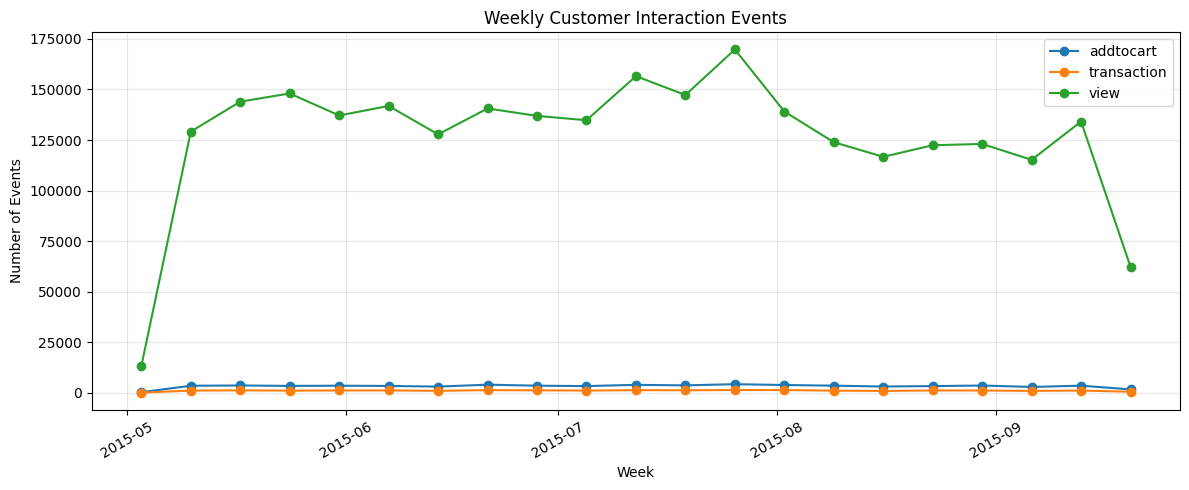

In [ ]:

import matplotlib.pyplot as plt

events["event_datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

weekly = (
    events.set_index("event_datetime")
    .groupby("event")
    .resample("W")
    .size()
    .unstack(level=0, fill_value=0)
)

print("SỐ SỰ KIỆN THEO TUẦN")
display(weekly.tail(10))

plt.figure(figsize=(12, 5))

for col in weekly.columns:
    plt.plot(
        weekly.index,
        weekly[col],
        marker="o",
        label=col
    )

plt.title("Weekly Customer Interaction Events")
plt.xlabel("Week")
plt.ylabel("Number of Events")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# Sử dụng DataFrame events từ bước trước
# Thời điểm dự đoán cố định để thử nghiệm
cutoff = pd.Timestamp("2015-08-01", tz="UTC")

observation_start = cutoff - pd.Timedelta(days=7)
prediction_end = cutoff + pd.Timedelta(days=7)

# 1. Lấy dữ liệu quan sát trong 7 ngày trước
history = events[
    (events["event_datetime"] >= observation_start)
    & (events["event_datetime"] < cutoff)
    & (events["event"].isin(["view", "addtocart"]))
].copy()

# 2. Tạo cặp user-item ứng viên
candidates = (
    history[["visitorid", "itemid"]]
    .drop_duplicates()
    .copy()
)

# 3. Xác định giao dịch xảy ra trong 7 ngày sau
future_purchases = (
    events.loc[
        (events["event_datetime"] >= cutoff)
        & (events["event_datetime"] < prediction_end)
        & (events["event"] == "transaction"),
        ["visitorid", "itemid"]
    ]
    .drop_duplicates()
    .copy()
)

future_purchases["purchase_intention"] = 1

# 4. Nối nhãn với cặp user-item đã quan sát
ml2_sample = candidates.merge(
    future_purchases,
    on=["visitorid", "itemid"],
    how="left",
    validate="one_to_one"
)

ml2_sample["purchase_intention"] = (
    ml2_sample["purchase_intention"]
    .fillna(0)
    .astype("int8")
)

print("KẾT QUẢ TẠO NHÃN ML2")
print("=" * 65)

print("Thời điểm dự đoán:", cutoff)
print("Số sự kiện quan sát:", len(history))
print("Số cặp user-item:", len(ml2_sample))

print("\nPHÂN BỐ NHÃN:")
print(
    ml2_sample["purchase_intention"]
    .value_counts()
)

print("\nTỶ LỆ NHÃN (%):")
print(
    ml2_sample["purchase_intention"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

print("\n5 DÒNG ĐẦU:")
display(ml2_sample.head())


KẾT QUẢ TẠO NHÃN ML2
Thời điểm dự đoán: 2015-08-01 00:00:00+00:00
Số sự kiện quan sát: 172009
Số cặp user-item: 139217

PHÂN BỐ NHÃN:
purchase_intention
0    139163
1        54
Name: count, dtype: int64

TỶ LỆ NHÃN (%):
purchase_intention
0    99.9612
1     0.0388
Name: proportion, dtype: float64

5 DÒNG ĐẦU:


,visitorid,itemid,purchase_intention
0,26,164342,0
1,42,60399,0
2,46,3780,0
3,79,450209,0
4,89,26210,0


In [ ]:

positive = ml2_sample[
    ml2_sample["purchase_intention"] == 1
]

negative = ml2_sample[
    ml2_sample["purchase_intention"] == 0
]

print("KIỂM TRA NHÃN ML2")
print("=" * 65)

print("Số mẫu dương:", len(positive))
print("Số mẫu âm:", len(negative))

print(
    "Tỷ lệ mẫu dương:",
    f"{len(positive)/len(ml2_sample)*100:.4f}%"
)

print(
    "\nSố user có nhãn dương:",
    positive["visitorid"].nunique()
)

print(
    "Số item có nhãn dương:",
    positive["itemid"].nunique()
)

# Kiểm tra có trùng cặp user-item không
print(
    "\nSố cặp user-item bị trùng:",
    ml2_sample.duplicated(
        ["visitorid", "itemid"]
    ).sum()
)

# Kiểm tra biên thời gian
print("\nKhoảng quan sát:")
print(
    history["event_datetime"].min(),
    "đến",
    history["event_datetime"].max()
)

print("\nKiểm tra giới hạn thời gian:",
      history["event_datetime"].max() < cutoff)

# Kiểm tra giao dịch tương lai có đủ cửa sổ
print(
    "Cửa sổ dự đoán nằm trong dữ liệu:",
    prediction_end <= events["event_datetime"].max()
)


KIỂM TRA NHÃN ML2
Số mẫu dương: 54
Số mẫu âm: 139163
Tỷ lệ mẫu dương: 0.0388%

Số user có nhãn dương: 38
Số item có nhãn dương: 50

Số cặp user-item bị trùng: 0

Khoảng quan sát:
2015-07-25 00:00:02.779000+00:00 đến 2015-07-31 23:59:58.354000+00:00

Kiểm tra giới hạn thời gian: True
Cửa sổ dự đoán nằm trong dữ liệu: True


In [ ]:

import pandas as pd

# Dùng events từ các ô code trước
# Đảm bảo đã có cột event_datetime

if "event_datetime" not in events.columns:
    events["event_datetime"] = pd.to_datetime(
        events["timestamp"],
        unit="ms",
        utc=True
    )

# Các mốc dự đoán thử nghiệm
cutoffs = pd.to_datetime([
    "2015-06-15",
    "2015-07-01",
    "2015-07-15",
    "2015-08-01",
    "2015-08-15",
    "2015-09-01"
], utc=True)

observation_windows = [7, 14, 21]
prediction_days = 7

results = []

for cutoff in cutoffs:

    future = events[
        (events["event_datetime"] >= cutoff)
        & (
            events["event_datetime"]
            < cutoff + pd.Timedelta(days=prediction_days)
        )
        & (events["event"] == "transaction")
    ][["visitorid", "itemid"]].drop_duplicates()

    future_keys = pd.MultiIndex.from_frame(future)

    for obs_days in observation_windows:

        history = events[
            (
                events["event_datetime"]
                >= cutoff - pd.Timedelta(days=obs_days)
            )
            & (events["event_datetime"] < cutoff)
            & (events["event"].isin(["view", "addtocart"]))
        ]

        candidates = history[
            ["visitorid", "itemid"]
        ].drop_duplicates()

        candidate_keys = pd.MultiIndex.from_frame(
            candidates
        )

        labels = candidate_keys.isin(future_keys)

        positive = int(labels.sum())
        total = len(candidates)
        negative = total - positive

        results.append({
            "cutoff": cutoff.date(),
            "observation_days": obs_days,
            "prediction_days": prediction_days,
            "total_samples": total,
            "positive": positive,
            "negative": negative,
            "positive_rate_%": round(
                positive / total * 100, 4
            ) if total > 0 else 0
        })

window_comparison = pd.DataFrame(results)

print("SO SÁNH CÁC CỬA SỔ DỰ ĐOÁN ML2")
display(window_comparison)

print("\nTỔNG HỢP THEO CỬA SỔ QUAN SÁT")
display(
    window_comparison.groupby(
        "observation_days"
    ).agg(
        total_samples=("total_samples", "sum"),
        positive=("positive", "sum"),
        mean_positive_rate=(
            "positive_rate_%", "mean"
        )
    )
)


SO SÁNH CÁC CỬA SỔ DỰ ĐOÁN ML2


,cutoff,observation_days,prediction_days,total_samples,positive,negative,positive_rate_%
0,2015-06-15,7,7,104820,44,104776,0.0420
1,2015-06-15,14,7,217867,58,217809,0.0266
2,2015-06-15,21,7,328065,61,328004,0.0186
3,2015-07-01,7,7,109440,55,109385,0.0503
4,2015-07-01,14,7,220889,71,220818,0.0321
5,2015-07-01,21,7,324142,80,324062,0.0247
6,2015-07-15,7,7,136738,60,136678,0.0439
7,2015-07-15,14,7,247069,70,246999,0.0283
8,2015-07-15,21,7,353887,76,353811,0.0215
9,2015-08-01,7,7,139217,54,139163,0.0388



TỔNG HỢP THEO CỬA SỔ QUAN SÁT


,total_samples,positive,mean_positive_rate
observation_days,,,
7,689409,288,0.041717
14,1345748,363,0.026883
21,2030670,401,0.019733


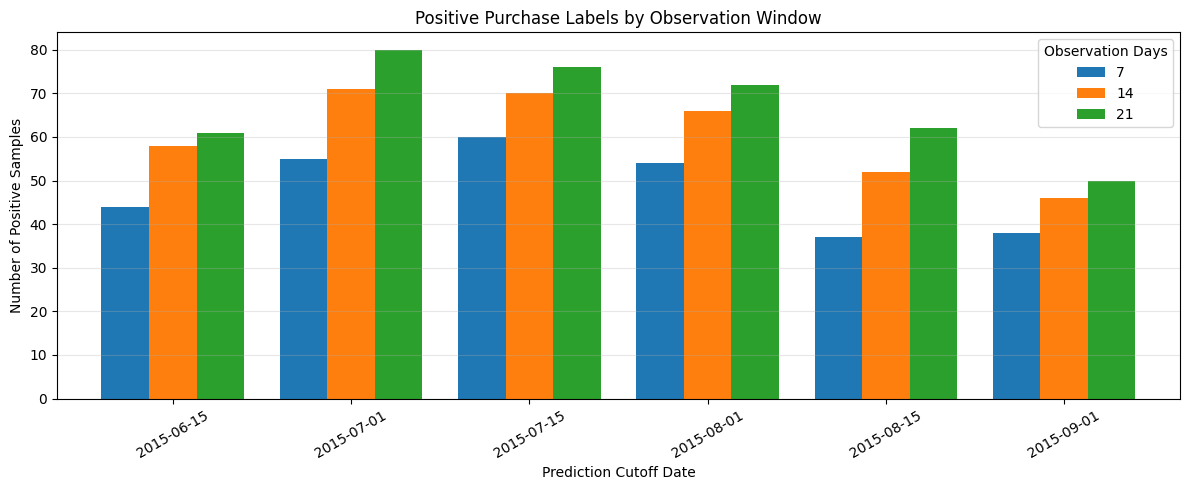

In [ ]:

import matplotlib.pyplot as plt

pivot = window_comparison.pivot(
    index="cutoff",
    columns="observation_days",
    values="positive"
)

ax = pivot.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title(
    "Positive Purchase Labels by Observation Window"
)
plt.xlabel("Prediction Cutoff Date")
plt.ylabel("Number of Positive Samples")
plt.legend(title="Observation Days")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

print("KIỂM TRA HÀNH VI TRONG PHIÊN")
print("=" * 65)

df = events[
    ["visitorid", "session_id", "itemid",
     "timestamp", "event"]
].copy()

df = df.sort_values(
    ["visitorid", "session_id", "itemid", "timestamp"],
    kind="mergesort"
)

# Thời điểm xem và thêm giỏ đầu tiên
interaction = df[
    df["event"].isin(["view", "addtocart"])
]

first_interaction = (
    interaction.groupby(
        ["visitorid", "session_id", "itemid"],
        as_index=False
    )["timestamp"]
    .min()
    .rename(columns={
        "timestamp": "first_interaction_time"
    })
)

# Các sự kiện mua
purchases = df[
    df["event"] == "transaction"
].copy()

# Nối sự kiện mua với lần tương tác đầu tiên
check = purchases.merge(
    first_interaction,
    on=["visitorid", "session_id", "itemid"],
    how="left",
    validate="many_to_one"
)

# Chỉ tính tương tác xảy ra trước mua
check["has_prior_interaction"] = (
    check["first_interaction_time"].notna()
    & (
        check["first_interaction_time"]
        < check["timestamp"]
    )
)

n = len(check)

print("Tổng sự kiện mua:", n)

print(
    "Sự kiện mua có tương tác trước đó cùng phiên:",
    int(check["has_prior_interaction"].sum())
)

print(
    "Tỷ lệ (%):",
    round(
        check["has_prior_interaction"].mean() * 100, 2
    )
)

print("\nSố phiên có mua hàng:")
print(
    purchases["session_id"].nunique()
)

print("\nSố phiên có mua sau tương tác cùng sản phẩm:")
print(
    check.loc[
        check["has_prior_interaction"],
        "session_id"
    ].nunique()
)

print("\nTHỐNG KÊ THỜI GIAN TỪ TƯƠNG TÁC ĐẾN MUA")

matched = check[
    check["has_prior_interaction"]
].copy()

matched["minutes_to_purchase"] = (
    matched["timestamp"]
    - matched["first_interaction_time"]
) / 60000

if not matched.empty:
    print(
        matched["minutes_to_purchase"].describe(
            percentiles=[.25, .5, .75, .9]
        )
    )
else:
    print("Không có giao dịch phù hợp.")


KIỂM TRA HÀNH VI TRONG PHIÊN
Tổng sự kiện mua: 22456
Sự kiện mua có tương tác trước đó cùng phiên: 20060
Tỷ lệ (%): 89.33

Số phiên có mua hàng:
14296

Số phiên có mua sau tương tác cùng sản phẩm:
13285

THỐNG KÊ THỜI GIAN TỪ TƯƠNG TÁC ĐẾN MUA
count    20060.000000
mean        11.507783
std         14.727663
min          0.046017
25%          3.267346
50%          6.238942
75%         14.022458
90%         27.251235
max        257.091900
Name: minutes_to_purchase, dtype: float64


In [ ]:

print("PHÂN BỐ PHIÊN TRUY CẬP")
print("=" * 65)

session_summary = (
    events.groupby("session_id")
    .agg(
        total_events=("event", "size"),
        has_purchase=(
            "event",
            lambda x: (x == "transaction").any()
        )
    )
)

print("Tổng số phiên:", len(session_summary))

print("\nSố phiên có và không có mua:")
print(
    session_summary["has_purchase"].value_counts()
)

print("\nTỷ lệ phiên có mua (%):")
print(
    round(
        session_summary["has_purchase"].mean()
        * 100, 4
    )
)

print("\nSố tương tác mỗi phiên:")
print(
    session_summary["total_events"].describe(
        percentiles=[.5, .75, .9, .95, .99]
    )
)


PHÂN BỐ PHIÊN TRUY CẬP
Tổng số phiên: 1761674

Số phiên có và không có mua:
has_purchase
False    1747378
True       14296
Name: count, dtype: int64

Tỷ lệ phiên có mua (%):
0.8115

Số tương tác mỗi phiên:
count    1.761674e+06
mean     1.564215e+00
std      2.599173e+00
min      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
90%      2.000000e+00
95%      4.000000e+00
99%      9.000000e+00
max      4.170000e+02
Name: total_events, dtype: float64


In [ ]:

import pandas as pd

print("XÂY DỰNG NHÃN MUA HÀNG THEO PHIÊN")
print("=" * 65)

# 1. Chuẩn bị dữ liệu sự kiện
df = events[
    ["visitorid", "session_id", "itemid",
     "timestamp", "event"]
].copy()

# Sắp xếp theo thứ tự thời gian
df = df.sort_values(
    ["visitorid", "session_id", "timestamp"],
    kind="mergesort"
)

# 2. Tìm tương tác đầu tiên với từng sản phẩm
interactions = df[
    df["event"].isin(["view", "addtocart"])
]

first_interactions = (
    interactions.groupby(
        ["visitorid", "session_id", "itemid"],
        as_index=False
    )
    .agg(
        prediction_timestamp=("timestamp", "min"),
        first_event=("event", "first")
    )
)

print(
    "Số mẫu ứng viên:",
    f"{len(first_interactions):,}"
)

# 3. Xác định thời điểm mua đầu tiên
purchases = df[
    df["event"] == "transaction"
]

first_purchases = (
    purchases.groupby(
        ["visitorid", "session_id", "itemid"],
        as_index=False
    )["timestamp"]
    .min()
    .rename(columns={
        "timestamp": "purchase_timestamp"
    })
)

# 4. Nối thông tin giao dịch
ml2_session = first_interactions.merge(
    first_purchases,
    on=["visitorid", "session_id", "itemid"],
    how="left",
    validate="one_to_one"
)

# 5. Tạo nhãn
ml2_session["purchase_intention"] = (
    ml2_session["purchase_timestamp"].notna()
    & (
        ml2_session["purchase_timestamp"]
        > ml2_session["prediction_timestamp"]
    )
).astype("int8")

# 6. Thống kê
print("\nPHÂN BỐ NHÃN:")
print(
    ml2_session["purchase_intention"]
    .value_counts()
)

print("\nTỶ LỆ NHÃN (%):")
print(
    ml2_session["purchase_intention"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

print("\n5 DÒNG ĐẦU:")
display(ml2_session.head())


XÂY DỰNG NHÃN MUA HÀNG THEO PHIÊN
Số mẫu ứng viên: 2,345,813

PHÂN BỐ NHÃN:
purchase_intention
0    2326365
1      19448
Name: count, dtype: int64

TỶ LỆ NHÃN (%):
purchase_intention
0    99.1709
1     0.8291
Name: proportion, dtype: float64

5 DÒNG ĐẦU:


,visitorid,session_id,itemid,prediction_timestamp,first_event,purchase_timestamp,purchase_intention
0,1,1_1,72028,1439487966444,view,NaN,0
1,2,2_1,216305,1438970468920,view,NaN,0
2,2,2_1,259884,1438970212664,view,NaN,0
3,2,2_1,325215,1438969904567,view,NaN,0
4,2,2_1,342816,1438970905669,view,NaN,0


In [ ]:

print("KIỂM TRA CHẤT LƯỢNG NHÃN THEO PHIÊN")
print("=" * 65)

positive = ml2_session[
    ml2_session["purchase_intention"] == 1
]

negative = ml2_session[
    ml2_session["purchase_intention"] == 0
]

print("Tổng số mẫu:", len(ml2_session))
print("Số mẫu dương:", len(positive))
print("Số mẫu âm:", len(negative))

print(
    "Tỷ lệ mẫu dương:",
    f"{len(positive)/len(ml2_session)*100:.4f}%"
)

print(
    "\nSố người dùng có nhãn dương:",
    positive["visitorid"].nunique()
)

print(
    "Số sản phẩm có nhãn dương:",
    positive["itemid"].nunique()
)

print(
    "Số phiên có nhãn dương:",
    positive["session_id"].nunique()
)

print(
    "\nSố cặp user-session-item bị trùng:",
    ml2_session.duplicated(
        ["visitorid", "session_id", "itemid"]
    ).sum()
)

print("\nPhân bố nhãn theo sự kiện đầu tiên:")
display(
    pd.crosstab(
        ml2_session["first_event"],
        ml2_session["purchase_intention"],
        normalize="index"
    ).mul(100).round(4)
)


KIỂM TRA CHẤT LƯỢNG NHÃN THEO PHIÊN
Tổng số mẫu: 2345813
Số mẫu dương: 19448
Số mẫu âm: 2326365
Tỷ lệ mẫu dương: 0.8291%

Số người dùng có nhãn dương: 10861
Số sản phẩm có nhãn dương: 11189
Số phiên có nhãn dương: 13260

Số cặp user-session-item bị trùng: 0

Phân bố nhãn theo sự kiện đầu tiên:


purchase_intention,0,1
first_event,,
addtocart,85.3168,14.6832
view,99.2837,0.7163


In [ ]:

import pandas as pd
import numpy as np

print("KIỂM TRA THỜI ĐIỂM DỰ ĐOÁN ML2")
print("=" * 70)

# 1. Kiểm tra thời điểm mua có sau thời điểm dự đoán
positive = ml2_session[
    ml2_session["purchase_intention"] == 1
].copy()

positive["minutes_to_purchase"] = (
    positive["purchase_timestamp"]
    - positive["prediction_timestamp"]
) / 60000

print("Số mẫu dương:", len(positive))

print("\nTHỜI GIAN TỪ DỰ ĐOÁN ĐẾN MUA (PHÚT)")
print(
    positive["minutes_to_purchase"].describe(
        percentiles=[.25, .5, .75, .90, .95, .99]
    )
)

print("\nKIỂM TRA NHÃN")

print(
    "Mẫu dương có thời gian mua <= dự đoán:",
    (positive["minutes_to_purchase"] <= 0).sum()
)

print(
    "Mẫu dương thiếu thời gian mua:",
    positive["purchase_timestamp"].isna().sum()
)

# 2. Kiểm tra timestamp đồng thời
transactions = events[
    events["event"] == "transaction"
][["visitorid", "session_id", "itemid",
   "timestamp"]].drop_duplicates()

same_time = first_interactions.merge(
    transactions,
    on=["visitorid", "session_id", "itemid"],
    how="inner"
)

same_time_count = (
    same_time["timestamp"]
    == same_time["prediction_timestamp"]
).sum()

print("\nSố trường hợp tương tác và mua cùng timestamp:",
      same_time_count)

# 3. Kiểm tra phân bố sự kiện đầu tiên
print("\nPHÂN BỐ FIRST EVENT:")
display(
    ml2_session["first_event"].value_counts()
)

print("\nTỶ LỆ NHÃN THEO FIRST EVENT:")
display(
    pd.crosstab(
        ml2_session["first_event"],
        ml2_session["purchase_intention"],
        margins=True
    )
)


KIỂM TRA THỜI ĐIỂM DỰ ĐOÁN ML2
Số mẫu dương: 19448

THỜI GIAN TỪ DỰ ĐOÁN ĐẾN MUA (PHÚT)
count    19448.000000
mean        11.052604
std         14.018306
min          0.046017
25%          3.215212
50%          6.072367
75%         13.415600
90%         26.258248
95%         36.321416
99%         65.600852
max        257.091900
Name: minutes_to_purchase, dtype: float64

KIỂM TRA NHÃN
Mẫu dương có thời gian mua <= dự đoán: 0
Mẫu dương thiếu thời gian mua: 0

Số trường hợp tương tác và mua cùng timestamp: 0

PHÂN BỐ FIRST EVENT:


,count
first_event,
view,2326873
addtocart,18940



TỶ LỆ NHÃN THEO FIRST EVENT:


purchase_intention,0,1,All
first_event,,,
addtocart,16159,2781,18940
view,2310206,16667,2326873
All,2326365,19448,2345813


In [ ]:

print("KIỂM TRA PHÂN BỐ NHÃN THEO THỜI GIAN")
print("=" * 70)

ml2_session["prediction_datetime"] = pd.to_datetime(
    ml2_session["prediction_timestamp"],
    unit="ms",
    utc=True
)

ml2_session["prediction_month"] = (
    ml2_session["prediction_datetime"]
    .dt.strftime("%Y-%m")
)

monthly_labels = (
    ml2_session.groupby("prediction_month")
    .agg(
        total_samples=("purchase_intention", "size"),
        positive_samples=("purchase_intention", "sum")
    )
    .reset_index()
)

monthly_labels["negative_samples"] = (
    monthly_labels["total_samples"]
    - monthly_labels["positive_samples"]
)

monthly_labels["positive_rate_%"] = (
    monthly_labels["positive_samples"]
    / monthly_labels["total_samples"]
    * 100
).round(4)

display(monthly_labels)

print("\nTHỜI GIAN DỰ ĐOÁN:")
print("Bắt đầu:", ml2_session["prediction_datetime"].min())
print("Kết thúc:", ml2_session["prediction_datetime"].max())

# Kiểm tra phiên truy cập có trải qua nhiều ngày không
session_bounds = (
    events.groupby("session_id")["timestamp"]
    .agg(["min", "max"])
)

session_duration_hours = (
    session_bounds["max"] - session_bounds["min"]
) / 3600000

print("\nTHỜI LƯỢNG PHIÊN (GIỜ):")
print(
    session_duration_hours.describe(
        percentiles=[.50, .90, .95, .99]
    )
)

print("\nSố phiên kéo dài hơn 24 giờ:")
print((session_duration_hours > 24).sum())


KIỂM TRA PHÂN BỐ NHÃN THEO THỜI GIAN


,prediction_month,total_samples,positive_samples,negative_samples,positive_rate_%
0,2015-05,499435,4039,495396,0.8087
1,2015-06,512200,4446,507754,0.8680
2,2015-07,596632,4924,591708,0.8253
3,2015-08,475125,4004,471121,0.8427
4,2015-09,262421,2035,260386,0.7755



THỜI GIAN DỰ ĐOÁN:
Bắt đầu: 2015-05-03 03:00:04.384000+00:00
Kết thúc: 2015-09-18 02:59:41.778000+00:00

THỜI LƯỢNG PHIÊN (GIỜ):
count    1.761674e+06
mean     2.923422e-02
std      1.387583e-01
min      0.000000e+00
50%      0.000000e+00
90%      5.921103e-02
95%      1.733745e-01
99%      4.979274e-01
max      1.214007e+01
dtype: float64

Số phiên kéo dài hơn 24 giờ:
0


In [ ]:

import pandas as pd
import numpy as np
import gc

print("BƯỚC 5A - CHUẨN BỊ FEATURE ENGINEERING")
print("=" * 65)

# Lấy các tương tác có thể quan sát được
interactions_fe = events.loc[
    events["event"].isin(["view", "addtocart"]),
    [
        "visitorid", "session_id", "itemid",
        "timestamp", "event"
    ]
].copy()

# Sắp xếp theo thời gian
interactions_fe = interactions_fe.sort_values(
    ["timestamp", "visitorid", "session_id", "itemid"],
    kind="mergesort"
).reset_index(drop=True)

# Mã hóa loại hành vi
interactions_fe["is_view"] = (
    interactions_fe["event"] == "view"
).astype("int8")

interactions_fe["is_cart"] = (
    interactions_fe["event"] == "addtocart"
).astype("int8")

# Kiểm tra sự kiện cùng thời điểm trên cùng user-item
same_time_count = interactions_fe.duplicated(
    ["visitorid", "itemid", "timestamp"],
    keep=False
).sum()

print("Số sự kiện View/Add-to-cart:",
      f"{len(interactions_fe):,}")

print("Số người dùng:",
      f"{interactions_fe['visitorid'].nunique():,}")

print("Số sản phẩm:",
      f"{interactions_fe['itemid'].nunique():,}")

print("Số dòng thuộc nhóm trùng user-item-timestamp:",
      f"{same_time_count:,}")

print("\n5 DÒNG ĐẦU:")
display(interactions_fe.head())


BƯỚC 5A - CHUẨN BỊ FEATURE ENGINEERING
Số sự kiện View/Add-to-cart: 2,733,181
Số người dùng: 1,407,499
Số sản phẩm: 235,060
Số dòng thuộc nhóm trùng user-item-timestamp: 22

5 DÒNG ĐẦU:


,visitorid,session_id,itemid,timestamp,event,is_view,is_cart
0,693516,693516_1,297662,1430622004384,addtocart,0,1
1,829044,829044_1,60987,1430622011289,view,1,0
2,652699,652699_1,252860,1430622013048,view,1,0
3,1125936,1125936_1,33661,1430622024154,view,1,0
4,693516,693516_1,297662,1430622026228,view,1,0


In [ ]:

print("TẠO ĐẶC TRƯNG LỊCH SỬ HÀNH VI")
print("=" * 65)

df = interactions_fe

# Hàm đếm lịch sử theo nhóm.
# Toàn bộ sự kiện cùng timestamp trong một nhóm
# được tính tại cùng mốc; không tính chúng là quá khứ
# của nhau.
def prior_count(data, keys, value_col):
    time_keys = keys + ["timestamp"]

    counts = data.groupby(
        time_keys, sort=False
    )[value_col].transform("sum")

    cumulative = data.groupby(
        keys, sort=False
    )[value_col].cumsum()

    # Với nhóm cùng timestamp, lấy tổng tích lũy
    # tại sự kiện cuối rồi trừ tổng sự kiện cùng thời điểm
    cumulative_end = cumulative.groupby(
        [data[k] for k in time_keys],
        sort=False
    ).transform("max")

    return (cumulative_end - counts).astype("int32")

# 1. Lịch sử người dùng
df["user_prior_views"] = prior_count(
    df, ["visitorid"], "is_view"
)

df["user_prior_carts"] = prior_count(
    df, ["visitorid"], "is_cart"
)

# 2. Lịch sử sản phẩm
df["item_prior_views"] = prior_count(
    df, ["itemid"], "is_view"
)

df["item_prior_carts"] = prior_count(
    df, ["itemid"], "is_cart"
)

# 3. Lịch sử của cặp user-item
df["prior_view_count"] = prior_count(
    df, ["visitorid", "itemid"], "is_view"
)

df["prior_cart_count"] = prior_count(
    df, ["visitorid", "itemid"], "is_cart"
)

print("Đã tạo 6 đặc trưng lịch sử.")

feature_cols = [
    "user_prior_views",
    "user_prior_carts",
    "item_prior_views",
    "item_prior_carts",
    "prior_view_count",
    "prior_cart_count"
]

print("\nTHỐNG KÊ ĐẶC TRƯNG:")
display(
    df[feature_cols].describe().round(2)
)

print("\nKIỂM TRA GIÁ TRỊ ÂM:")
print((df[feature_cols] < 0).sum())

gc.collect()


TẠO ĐẶC TRƯNG LỊCH SỬ HÀNH VI
Đã tạo 6 đặc trưng lịch sử.

THỐNG KÊ ĐẶC TRƯNG:


,user_prior_views,user_prior_carts,item_prior_views,item_prior_carts,prior_view_count,prior_cart_count
count,2733181.00,2733181.00,2733181.00,2733181.00,2733181.00,2733181.00
mean,34.14,2.79,60.86,2.07,0.68,0.03
std,247.14,26.20,151.15,8.61,4.45,0.26
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,4.00,0.00,0.00,0.00
50%,0.00,0.00,17.00,0.00,0.00,0.00
75%,3.00,0.00,55.00,1.00,0.00,0.00
max,6478.00,719.00,3409.00,304.00,307.00,30.00



KIỂM TRA GIÁ TRỊ ÂM:
user_prior_views    0
user_prior_carts    0
item_prior_views    0
item_prior_carts    0
prior_view_count    0
prior_cart_count    0
dtype: int64


27

In [ ]:

print("GHÉP FEATURE VÀO DỮ LIỆU ML2")
print("=" * 65)

# Đánh dấu tương tác đầu tiên của từng user-session-item
first_rows = df.drop_duplicates(
    subset=["visitorid", "session_id", "itemid"],
    keep="first"
).copy()

# Tạo đặc trưng sự kiện đầu tiên
first_rows["first_event_cart"] = (
    first_rows["event"] == "addtocart"
).astype("int8")

# Chỉ giữ các cột cần thiết
cols_to_keep = [
    "visitorid", "session_id", "itemid",
    "timestamp", "first_event_cart"
] + feature_cols

first_rows = first_rows[cols_to_keep].rename(
    columns={"timestamp": "prediction_timestamp"}
)

# Ghép với bộ nhãn đã xây dựng
ml2_features = ml2_session.merge(
    first_rows,
    on=[
        "visitorid", "session_id",
        "itemid", "prediction_timestamp"
    ],
    how="left",
    validate="one_to_one"
)

print("Tổng số mẫu ban đầu:",
      f"{len(ml2_session):,}")

print("Tổng số mẫu sau ghép:",
      f"{len(ml2_features):,}")

print("\nSỐ GIÁ TRỊ THIẾU TRONG FEATURE:")
print(
    ml2_features[
        ["first_event_cart"] + feature_cols
    ].isna().sum()
)

print("\nKIỂM TRA FIRST EVENT:")
mismatch = (
    ml2_features["first_event_cart"].notna()
    & (
        ml2_features["first_event_cart"]
        != ml2_features["first_event"].eq("addtocart")
    )
)

print("Số dòng không khớp first_event:",
      int(mismatch.sum()))

print("\n5 DÒNG ĐẦU:")
display(
    ml2_features[
        ["visitorid", "itemid",
         "first_event_cart",
         "user_prior_views",
         "user_prior_carts",
         "prior_view_count",
         "prior_cart_count",
         "purchase_intention"]
    ].head()
)


GHÉP FEATURE VÀO DỮ LIỆU ML2
Tổng số mẫu ban đầu: 2,345,813
Tổng số mẫu sau ghép: 2,345,813

SỐ GIÁ TRỊ THIẾU TRONG FEATURE:
first_event_cart    0
user_prior_views    0
user_prior_carts    0
item_prior_views    0
item_prior_carts    0
prior_view_count    0
prior_cart_count    0
dtype: int64

KIỂM TRA FIRST EVENT:
Số dòng không khớp first_event: 0

5 DÒNG ĐẦU:


,visitorid,itemid,first_event_cart,user_prior_views,user_prior_carts,prior_view_count,prior_cart_count,purchase_intention
0,1,72028,0,0,0,0,0,0
1,2,216305,0,3,0,0,0,0
2,2,259884,0,2,0,0,0,0
3,2,325215,0,0,0,0,0,0
4,2,342816,0,4,0,0,0,0


In [ ]:

print("TẠO ĐẶC TRƯNG THỜI GIAN")
print("=" * 65)

# Dữ liệu ml2_features từ Ô 21
ml2_features["prediction_datetime"] = pd.to_datetime(
    ml2_features["prediction_timestamp"],
    unit="ms",
    utc=True
)

# Giờ tương tác
ml2_features["hour"] = (
    ml2_features["prediction_datetime"].dt.hour
).astype("int8")

# Thứ trong tuần: Monday=0, Sunday=6
ml2_features["day_of_week"] = (
    ml2_features["prediction_datetime"].dt.dayofweek
).astype("int8")

print("THỐNG KÊ GIỜ TƯƠNG TÁC:")
display(
    ml2_features["hour"].value_counts()
    .sort_index()
)

print("\nTHỐNG KÊ THỨ TRONG TUẦN:")
display(
    ml2_features["day_of_week"].value_counts()
    .sort_index()
)

print("\nKIỂM TRA:")
print("Giá trị thiếu hour:",
      ml2_features["hour"].isna().sum())
print("Giá trị thiếu day_of_week:",
      ml2_features["day_of_week"].isna().sum())


TẠO ĐẶC TRƯNG THỜI GIAN
THỐNG KÊ GIỜ TƯƠNG TÁC:


,count
hour,
0,122142
1,119645
2,124264
3,129338
4,125613
5,102177
6,65694
7,37609
8,21999



THỐNG KÊ THỨ TRONG TUẦN:


,count
day_of_week,
0,372780
1,379694
2,365453
3,355253
4,324297
5,262093
6,286243



KIỂM TRA:
Giá trị thiếu hour: 0
Giá trị thiếu day_of_week: 0


In [ ]:

print("TẠO ĐẶC TRƯNG RECENCY VÀ PREVIOUS EVENT")
print("=" * 65)

# Gom tương tác theo user và timestamp
# Nếu cùng timestamp có nhiều loại sự kiện,
# sử dụng cờ any_cart thay vì đoán thứ tự.
user_times = (
    interactions_fe.groupby(
        ["visitorid", "timestamp"],
        as_index=False,
        sort=False
    )
    .agg(any_cart=("is_cart", "max"))
)

user_times = user_times.sort_values(
    ["visitorid", "timestamp"],
    kind="mergesort"
).reset_index(drop=True)

g = user_times.groupby("visitorid", sort=False)

# Timestamp tương tác ngay trước đó
user_times["previous_timestamp"] = (
    g["timestamp"].shift(1)
)

# Sự kiện trước đó có addtocart không
user_times["previous_event_cart"] = (
    g["any_cart"].shift(1)
    .fillna(0)
    .astype("int8")
)

# Recency bằng giờ
user_times["recency_hours"] = (
    (
        user_times["timestamp"]
        - user_times["previous_timestamp"]
    ) / 3600000
)

# Chưa có lịch sử: -1
user_times["recency_hours"] = (
    user_times["recency_hours"].fillna(-1)
    .astype("float32")
)

# Chỉ lấy feature cần thiết
time_features = user_times[
    [
        "visitorid",
        "timestamp",
        "previous_event_cart",
        "recency_hours"
    ]
].rename(columns={
    "timestamp": "prediction_timestamp"
})

# Ghép vào ML2
ml2_features = ml2_features.merge(
    time_features,
    on=["visitorid", "prediction_timestamp"],
    how="left",
    validate="many_to_one"
)

print("Tổng số mẫu:", len(ml2_features))

print("\nTHỐNG KÊ RECENCY:")
display(
    ml2_features["recency_hours"].describe(
        percentiles=[.25, .5, .75, .9, .99]
    )
)

print("\nPHÂN BỐ PREVIOUS EVENT CART:")
display(
    ml2_features["previous_event_cart"].value_counts()
)

print("\nGIÁ TRỊ THIẾU:")
print(
    ml2_features[
        ["recency_hours", "previous_event_cart"]
    ].isna().sum()
)


TẠO ĐẶC TRƯNG RECENCY VÀ PREVIOUS EVENT
Tổng số mẫu: 2345813

THỐNG KÊ RECENCY:


,recency_hours
count,2.345813e+06
mean,3.360175e+01
std,1.913214e+02
min,-1.000000e+00
25%,-1.000000e+00
50%,-1.000000e+00
75%,2.784556e-02
90%,1.174955e+01
99%,1.038973e+03
max,3.274292e+03



PHÂN BỐ PREVIOUS EVENT CART:


,count
previous_event_cart,
0,2317092
1,28721



GIÁ TRỊ THIẾU:
recency_hours          0
previous_event_cart    0
dtype: int64


In [ ]:

print("TẠO ĐẶC TRƯNG VIEW-TO-CART")
print("=" * 65)

# Mỗi user-item-timestamp là một mốc riêng
pair_times = (
    interactions_fe.groupby(
        ["visitorid", "itemid", "timestamp"],
        as_index=False,
        sort=False
    )
    .agg(
        has_view=("is_view", "max"),
        has_cart=("is_cart", "max")
    )
)

pair_times = pair_times.sort_values(
    ["visitorid", "itemid", "timestamp"],
    kind="mergesort"
).reset_index(drop=True)

pair_keys = ["visitorid", "itemid"]
g = pair_times.groupby(pair_keys, sort=False)

# Đã có View ở một timestamp sớm hơn chưa?
prior_view = (
    g["has_view"].cumsum()
    - pair_times["has_view"]
) > 0

# Có View trước lần Cart hiện tại không?
pair_times["view_to_cart_now"] = (
    prior_view & pair_times["has_cart"].eq(1)
).astype("int8")

# Cờ chuỗi đã hoàn thành trước timestamp hiện tại
completed = (
    pair_times.groupby(pair_keys, sort=False)
    ["view_to_cart_now"].cummax()
)

pair_times["user_view_to_cart_flag"] = (
    completed.groupby(
        [pair_times["visitorid"], pair_times["itemid"]],
        sort=False
    ).shift(1).fillna(0).astype("int8")
)

sequence_features = pair_times[
    [
        "visitorid", "itemid", "timestamp",
        "user_view_to_cart_flag"
    ]
].rename(columns={
    "timestamp": "prediction_timestamp"
})

ml2_features = ml2_features.merge(
    sequence_features,
    on=[
        "visitorid", "itemid",
        "prediction_timestamp"
    ],
    how="left",
    validate="many_to_one"
)

print("Tổng số mẫu:", len(ml2_features))

print("\nPHÂN BỐ VIEW-TO-CART FLAG:")
display(
    ml2_features["user_view_to_cart_flag"]
    .value_counts(dropna=False)
)

print("\nGIÁ TRỊ THIẾU:")
print(
    ml2_features[
        "user_view_to_cart_flag"
    ].isna().sum()
)


TẠO ĐẶC TRƯNG VIEW-TO-CART
Tổng số mẫu: 2345813

PHÂN BỐ VIEW-TO-CART FLAG:


,count
user_view_to_cart_flag,
0,2329714
1,16099



GIÁ TRỊ THIẾU:
0


In [ ]:

print("KIỂM TRA FEATURE ENGINEERING ML2")
print("=" * 65)

final_features = [
    "first_event_cart",
    "user_prior_views",
    "user_prior_carts",
    "item_prior_views",
    "item_prior_carts",
    "prior_view_count",
    "prior_cart_count",
    "hour",
    "day_of_week",
    "recency_hours",
    "previous_event_cart",
    "user_view_to_cart_flag"
]

print("Số mẫu:", f"{len(ml2_features):,}")
print("Số đặc trưng:", len(final_features))

print("\nGIÁ TRỊ THIẾU:")
display(
    ml2_features[final_features].isna().sum()
)

print("\nTHỐNG KÊ CÁC ĐẶC TRƯNG:")
display(
    ml2_features[final_features]
    .describe()
    .round(2)
    .T
)

print("\nPHÂN BỐ NHÃN:")
display(
    ml2_features["purchase_intention"].value_counts()
)

print("\nKIỂM TRA TRÙNG MẪU:")
print(
    ml2_features.duplicated(
        ["visitorid", "session_id", "itemid"]
    ).sum()
)

print("\nKIỂM TRA GIÁ TRỊ HỢP LỆ:")
print(
    "Recency âm ngoài giá trị -1:",
    (
        (ml2_features["recency_hours"] < 0)
        & (ml2_features["recency_hours"] != -1)
    ).sum()
)

print(
    "Số giá trị vô hạn:",
    np.isinf(
        ml2_features[final_features].to_numpy()
    ).sum()
)


KIỂM TRA FEATURE ENGINEERING ML2
Số mẫu: 2,345,813
Số đặc trưng: 12

GIÁ TRỊ THIẾU:


,0
first_event_cart,0
user_prior_views,0
user_prior_carts,0
item_prior_views,0
item_prior_carts,0
prior_view_count,0
prior_cart_count,0
hour,0
day_of_week,0
recency_hours,0



THỐNG KÊ CÁC ĐẶC TRƯNG:


,count,mean,std,min,25%,50%,75%,max
first_event_cart,2345813.0,0.01,0.09,0.0,0.0,0.0,0.00,1.00
user_prior_views,2345813.0,29.12,226.79,0.0,0.0,0.0,2.00,6478.00
user_prior_carts,2345813.0,2.26,23.76,0.0,0.0,0.0,0.00,719.00
item_prior_views,2345813.0,59.03,149.83,0.0,4.0,16.0,53.00,3409.00
item_prior_carts,2345813.0,1.87,7.93,0.0,0.0,0.0,1.00,304.00
prior_view_count,2345813.0,0.43,4.00,0.0,0.0,0.0,0.00,305.00
prior_cart_count,2345813.0,0.01,0.12,0.0,0.0,0.0,0.00,26.00
hour,2345813.0,12.77,7.86,0.0,4.0,16.0,20.00,23.00
day_of_week,2345813.0,2.77,1.97,0.0,1.0,3.0,4.00,6.00
recency_hours,2345813.0,33.60,191.32,-1.0,-1.0,-1.0,0.03,3274.29



PHÂN BỐ NHÃN:


,count
purchase_intention,
0,2326365
1,19448



KIỂM TRA TRÙNG MẪU:
0

KIỂM TRA GIÁ TRỊ HỢP LỆ:
Recency âm ngoài giá trị -1: 0
Số giá trị vô hạn: 0


In [ ]:

import numpy as np
import pandas as pd

print("HOÀN THIỆN FEATURE ENGINEERING")
print("=" * 65)

# 1. Người dùng đã có tương tác trước đó chưa?
ml2_features["has_prior_interaction"] = (
    ml2_features["recency_hours"] >= 0
).astype("int8")

# 2. Thời gian từ tương tác gần nhất
# Thay -1 bằng 0, sử dụng cờ ở trên để phân biệt
ml2_features["recency_hours_clean"] = (
    ml2_features["recency_hours"]
    .clip(lower=0)
    .astype("float32")
)

# 3. Biến đổi log cho các đặc trưng đếm
count_features = [
    "user_prior_views",
    "user_prior_carts",
    "item_prior_views",
    "item_prior_carts",
    "prior_view_count",
    "prior_cart_count"
]

for col in count_features:
    ml2_features[col + "_log"] = np.log1p(
        ml2_features[col]
    ).astype("float32")

print("Số đặc trưng log mới:", len(count_features))

print("\nPHÂN BỐ HAS PRIOR INTERACTION:")
display(
    ml2_features["has_prior_interaction"]
    .value_counts()
)

print("\nTHỐNG KÊ RECENCY SAU XỬ LÝ:")
display(
    ml2_features["recency_hours_clean"]
    .describe()
)

print("\nKIỂM TRA GIÁ TRỊ THIẾU:")
new_cols = (
    ["has_prior_interaction", "recency_hours_clean"]
    + [c + "_log" for c in count_features]
)

print(ml2_features[new_cols].isna().sum())

print("\nHOÀN THÀNH BỔ SUNG FEATURE")


HOÀN THIỆN FEATURE ENGINEERING
Số đặc trưng log mới: 6

PHÂN BỐ HAS PRIOR INTERACTION:


,count
has_prior_interaction,
0,1407556
1,938257



THỐNG KÊ RECENCY SAU XỬ LÝ:


,recency_hours_clean
count,2.345813e+06
mean,3.420177e+01
std,1.912968e+02
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,2.784556e-02
max,3.274292e+03



KIỂM TRA GIÁ TRỊ THIẾU:
has_prior_interaction    0
recency_hours_clean      0
user_prior_views_log     0
user_prior_carts_log     0
item_prior_views_log     0
item_prior_carts_log     0
prior_view_count_log     0
prior_cart_count_log     0
dtype: int64

HOÀN THÀNH BỔ SUNG FEATURE


PHÂN TÍCH FEATURE VÀ PURCHASE INTENTION


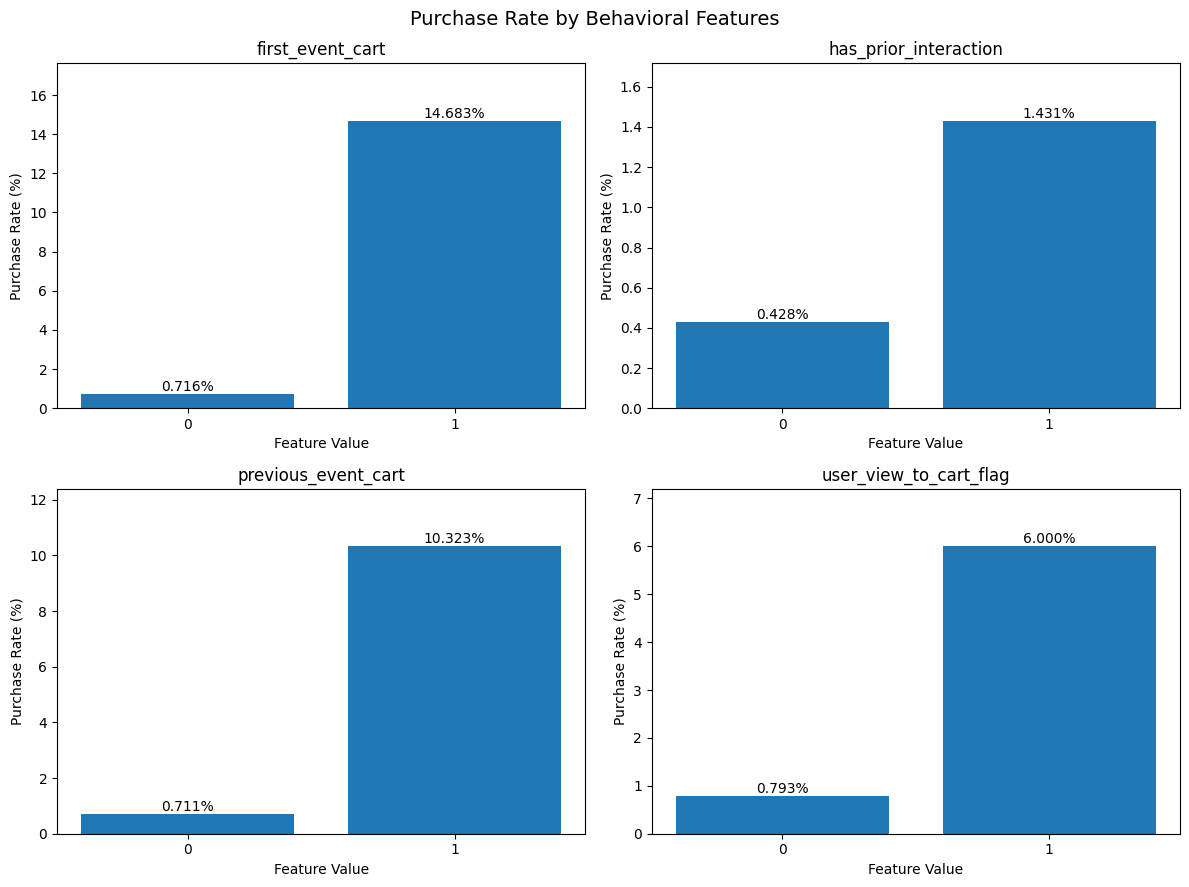


BẢNG THỐNG KÊ CHI TIẾT

FEATURE: first_event_cart


,total_samples,positive_samples,purchase_rate
first_event_cart,,,
0,2326873,16667,0.7163
1,18940,2781,14.6832



FEATURE: has_prior_interaction


,total_samples,positive_samples,purchase_rate
has_prior_interaction,,,
0,1407556,6025,0.4280
1,938257,13423,1.4306



FEATURE: previous_event_cart


,total_samples,positive_samples,purchase_rate
previous_event_cart,,,
0,2317092,16483,0.7114
1,28721,2965,10.3235



FEATURE: user_view_to_cart_flag


,total_samples,positive_samples,purchase_rate
user_view_to_cart_flag,,,
0,2329714,18482,0.7933
1,16099,966,6.0004


In [ ]:

import matplotlib.pyplot as plt

print("PHÂN TÍCH FEATURE VÀ PURCHASE INTENTION")
print("=" * 65)

# Nhóm đặc trưng cần kiểm tra
analysis_features = [
    "first_event_cart",
    "has_prior_interaction",
    "previous_event_cart",
    "user_view_to_cart_flag"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flatten(), analysis_features):

    summary = (
        ml2_features.groupby(feature)
        ["purchase_intention"]
        .agg(["mean", "sum", "count"])
    )

    summary["purchase_rate"] = summary["mean"] * 100

    bars = ax.bar(
        summary.index.astype(str),
        summary["purchase_rate"]
    )

    ax.set_title(feature)
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Purchase Rate (%)")

    for bar, rate in zip(
        bars, summary["purchase_rate"]
    ):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"{rate:.3f}%",
            ha="center",
            va="bottom"
        )

    ax.set_ylim(
        0,
        max(summary["purchase_rate"].max() * 1.2, 0.1)
    )

plt.suptitle(
    "Purchase Rate by Behavioral Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nBẢNG THỐNG KÊ CHI TIẾT")

for feature in analysis_features:
    print(f"\nFEATURE: {feature}")

    result = (
        ml2_features.groupby(feature)
        ["purchase_intention"]
        .agg(
            total_samples="count",
            positive_samples="sum",
            purchase_rate="mean"
        )
    )

    result["purchase_rate"] = (
        result["purchase_rate"] * 100
    ).round(4)

    display(result)


In [ ]:

print("KIỂM TRA NHÃN TRƯỚC HUẤN LUYỆN")
print("=" * 65)

# Lấy thời điểm giao dịch cuối cùng của từng
# user-session-item để kiểm tra có giao dịch
# nào xảy ra sau tương tác đầu tiên không
last_purchase = (
    events.loc[
        events["event"] == "transaction",
        ["visitorid", "session_id", "itemid", "timestamp"]
    ]
    .groupby(
        ["visitorid", "session_id", "itemid"],
        as_index=False
    )["timestamp"]
    .max()
    .rename(columns={"timestamp": "last_purchase_time"})
)

audit = ml2_features[
    ["visitorid", "session_id", "itemid",
     "prediction_timestamp", "purchase_intention"]
].merge(
    last_purchase,
    on=["visitorid", "session_id", "itemid"],
    how="left",
    validate="one_to_one"
)

correct_label = (
    audit["last_purchase_time"]
    > audit["prediction_timestamp"]
).fillna(False).astype("int8")

different = (
    correct_label.to_numpy()
    != ml2_features["purchase_intention"].to_numpy()
)

print("Số nhãn khác khi kiểm tra:", different.sum())
print("Nhãn dương ban đầu:",
      int(ml2_features["purchase_intention"].sum()))
print("Nhãn dương sau kiểm tra:",
      int(correct_label.sum()))

# Cập nhật nếu có trường hợp chưa được tính
ml2_features["purchase_intention"] = (
    correct_label.to_numpy()
)

del audit, last_purchase


KIỂM TRA NHÃN TRƯỚC HUẤN LUYỆN
Số nhãn khác khi kiểm tra: 66
Nhãn dương ban đầu: 19448
Nhãn dương sau kiểm tra: 19514


In [ ]:

import numpy as np
import pandas as pd

print("CHIA TRAIN - VALIDATION - TEST")
print("=" * 65)

# Mốc chia (Unix milliseconds, UTC)
val_start = pd.Timestamp("2015-08-01", tz="UTC").value // 10**6
test_start = pd.Timestamp("2015-09-01", tz="UTC").value // 10**6

# Xác định thời điểm bắt đầu và kết thúc phiên
session_bounds = (
    events.groupby("session_id")["timestamp"]
    .agg(session_start="min", session_end="max")
)

# Ghép vào tập ML2
split_data = ml2_features[
    ["session_id", "prediction_timestamp",
     "purchase_intention"]
].join(
    session_bounds,
    on="session_id"
)

t = split_data["prediction_timestamp"]
s = split_data["session_start"]
e = split_data["session_end"]

# Chỉ giữ phiên nằm hoàn toàn trong từng giai đoạn
train_mask = (s < val_start) & (e < val_start)
val_mask = (
    (s >= val_start)
    & (e < test_start)
)
test_mask = (s >= test_start)

# Kiểm tra từng mẫu nằm trong phiên hợp lệ
valid_time = (s <= t) & (t <= e)

train_mask = (train_mask & valid_time).to_numpy()
val_mask = (val_mask & valid_time).to_numpy()
test_mask = (test_mask & valid_time).to_numpy()

# Chưa tạo bản sao các bảng lớn
train_idx = np.flatnonzero(train_mask)
val_idx = np.flatnonzero(val_mask)
test_idx = np.flatnonzero(test_mask)

print("Tổng mẫu ban đầu:", f"{len(ml2_features):,}")
print("Train:", f"{len(train_idx):,}")
print("Validation:", f"{len(val_idx):,}")
print("Test:", f"{len(test_idx):,}")

excluded = (
    len(ml2_features)
    - len(train_idx)
    - len(val_idx)
    - len(test_idx)
)

print("Mẫu loại do ranh giới/thời gian:", excluded)

print("\nPHÂN BỐ NHÃN TỪNG TẬP")

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    labels = ml2_features.iloc[idx]["purchase_intention"]

    print(f"\n{name}")
    print("Tổng mẫu:", f"{len(labels):,}")
    print("Nhãn 0:", f"{(labels == 0).sum():,}")
    print("Nhãn 1:", f"{(labels == 1).sum():,}")
    print("Tỷ lệ dương:",
          f"{labels.mean()*100:.4f}%")

# Không dùng session_start/session_end làm feature
del split_data


CHIA TRAIN - VALIDATION - TEST
Tổng mẫu ban đầu: 2,345,813
Train: 1,608,194
Validation: 474,965
Test: 262,313
Mẫu loại do ranh giới/thời gian: 341

PHÂN BỐ NHÃN TỪNG TẬP

Train
Tổng mẫu: 1,608,194
Nhãn 0: 1,594,743
Nhãn 1: 13,451
Tỷ lệ dương: 0.8364%

Validation
Tổng mẫu: 474,965
Nhãn 0: 470,971
Nhãn 1: 3,994
Tỷ lệ dương: 0.8409%

Test
Tổng mẫu: 262,313
Nhãn 0: 260,275
Nhãn 1: 2,038
Tỷ lệ dương: 0.7769%


In [ ]:

import pandas as pd
import numpy as np

print("KIỂM TRA NHÃN PURCHASE_INTENTION")
print("=" * 60)

# Bước 1: Kiểm tra dữ liệu nhãn
df = ml2_features.copy()

required = [
    "visitorid", "session_id", "itemid",
    "prediction_timestamp", "purchase_intention"
]

missing = [c for c in required if c not in df.columns]
assert not missing, f"Thiếu cột: {missing}"

print("Tổng số mẫu:", len(df))
print("\nPhân bố nhãn:")
print(df["purchase_intention"].value_counts(dropna=False))

print("\nTỷ lệ nhãn (%):")
print(
    df["purchase_intention"]
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
)

invalid_labels = (~df["purchase_intention"].isin([0, 1])).sum()
duplicates = df.duplicated(
    ["visitorid", "session_id", "itemid"]
).sum()

print("\nNhãn không hợp lệ:", invalid_labels)
print("Mẫu trùng user-session-item:", duplicates)

# Bước 2: Lấy giao dịch từ bảng events gốc
tx = events.loc[
    events["event"].eq("transaction"),
    ["visitorid", "session_id", "itemid", "timestamp"]
].copy()

# Lấy thời điểm mua cuối cùng cho mỗi tổ hợp
keys = ["visitorid", "session_id", "itemid"]

last_tx = (
    tx.groupby(keys, as_index=False)["timestamp"]
    .max()
    .rename(columns={"timestamp": "last_transaction_time"})
)

# Bước 3: Đối chiếu với thời điểm dự đoán
audit = df[required].merge(
    last_tx,
    on=keys,
    how="left",
    validate="one_to_one"
)

# timestamp và prediction_timestamp phải cùng đơn vị
pred = pd.to_numeric(
    audit["prediction_timestamp"], errors="coerce"
)
last = pd.to_numeric(
    audit["last_transaction_time"], errors="coerce"
)

# Phát hiện chênh lệch đơn vị mili-giây / micro-giây
pred_med = pred.dropna().abs().median()
last_med = last.dropna().abs().median()

if pd.notna(pred_med) and pd.notna(last_med):
    ratio = pred_med / last_med
    if not (0.99 <= ratio <= 1.01):
        raise ValueError(
            "Hai cột thời gian có thể khác đơn vị. "
            f"Tỷ lệ trung vị = {ratio:.3f}. "
            "Cần kiểm tra trước khi đối chiếu nhãn."
        )

# Nhãn đúng nếu có ít nhất một giao dịch sau dự đoán
audit["expected_label"] = (
    last.gt(pred) & last.notna()
).astype(int)

audit["label_mismatch"] = (
    audit["purchase_intention"]
    != audit["expected_label"]
)

false_positive_label = (
    (audit["purchase_intention"] == 1)
    & (audit["expected_label"] == 0)
).sum()

false_negative_label = (
    (audit["purchase_intention"] == 0)
    & (audit["expected_label"] == 1)
).sum()

print("\nKẾT QUẢ ĐỐI CHIẾU")
print("-" * 60)
print("Nhãn 1 nhưng không có giao dịch hợp lệ:",
      false_positive_label)
print("Nhãn 0 nhưng có giao dịch hợp lệ:",
      false_negative_label)
print("Tổng số nhãn không khớp:",
      audit["label_mismatch"].sum())

print("\nBẢNG SO SÁNH")
print(
    pd.crosstab(
        audit["purchase_intention"],
        audit["expected_label"],
        rownames=["Nhãn hiện tại"],
        colnames=["Nhãn kiểm tra"]
    )
)

print("\nMỘT SỐ MẪU KHÔNG KHỚP (NẾU CÓ)")
display(
    audit.loc[
        audit["label_mismatch"],
        required + ["last_transaction_time", "expected_label"]
    ].head(10)
)

print("\nHOÀN THÀNH KIỂM TRA NHÃN!")


KIỂM TRA NHÃN PURCHASE_INTENTION
Tổng số mẫu: 2345813

Phân bố nhãn:
purchase_intention
0    2326299
1      19514
Name: count, dtype: int64

Tỷ lệ nhãn (%):
purchase_intention
0    99.1681
1     0.8319
Name: proportion, dtype: float64

Nhãn không hợp lệ: 0
Mẫu trùng user-session-item: 0

KẾT QUẢ ĐỐI CHIẾU
------------------------------------------------------------
Nhãn 1 nhưng không có giao dịch hợp lệ: 0
Nhãn 0 nhưng có giao dịch hợp lệ: 0
Tổng số nhãn không khớp: 0

BẢNG SO SÁNH
Nhãn kiểm tra        0      1
Nhãn hiện tại                
0              2326299      0
1                    0  19514

MỘT SỐ MẪU KHÔNG KHỚP (NẾU CÓ)


,visitorid,session_id,itemid,prediction_timestamp,purchase_intention,last_transaction_time,expected_label



HOÀN THÀNH KIỂM TRA NHÃN!


In [ ]:

print("KIỂM TRA NHÃN SAU PHÂN CHIA")
print("=" * 55)

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    subset = ml2_features.iloc[idx]
    positives = int(subset["purchase_intention"].sum())
    total = len(subset)

    print(f"\n{name}")
    print(f"Tổng mẫu: {total:,}")
    print(f"Nhãn 1: {positives:,}")
    print(f"Nhãn 0: {total - positives:,}")
    print(f"Tỷ lệ nhãn 1: {positives/total*100:.4f}%")

print("\nTỔNG NHÃN DƯƠNG TRONG 3 TẬP:",
      int(ml2_features.iloc[
          np.concatenate([train_idx, val_idx, test_idx])
      ]["purchase_intention"].sum()))


KIỂM TRA NHÃN SAU PHÂN CHIA

Train
Tổng mẫu: 1,608,194
Nhãn 1: 13,451
Nhãn 0: 1,594,743
Tỷ lệ nhãn 1: 0.8364%

Validation
Tổng mẫu: 474,965
Nhãn 1: 3,994
Nhãn 0: 470,971
Tỷ lệ nhãn 1: 0.8409%

Test
Tổng mẫu: 262,313
Nhãn 1: 2,038
Nhãn 0: 260,275
Tỷ lệ nhãn 1: 0.7769%

TỔNG NHÃN DƯƠNG TRONG 3 TẬP: 19483


In [ ]:

import numpy as np
import pandas as pd

print("KIỂM TRA 13 ĐẶC TRƯNG ML2")
print("=" * 65)

features = [
    "first_event_cart",
    "user_prior_views_log",
    "user_prior_carts_log",
    "item_prior_views_log",
    "item_prior_carts_log",
    "prior_view_count_log",
    "prior_cart_count_log",
    "hour",
    "day_of_week",
    "has_prior_interaction",
    "recency_hours_clean",
    "previous_event_cart",
    "user_view_to_cart_flag"
]

df = ml2_features

# 1. Kiểm tra số lượng và tên đặc trưng
missing_cols = [c for c in features if c not in df.columns]

print("\n1. SỐ LƯỢNG ĐẶC TRƯNG")
print("Số đặc trưng yêu cầu:", len(features))
print("Số đặc trưng tìm thấy:",
      len(features) - len(missing_cols))
print("Các cột bị thiếu:", missing_cols)

if missing_cols:
    raise ValueError("Thiếu đặc trưng trong dữ liệu!")

X = df[features].copy()

# 2. Kiểm tra NaN và Inf
print("\n2. KIỂM TRA GIÁ TRỊ THIẾU VÀ VÔ HẠN")

X_numeric = X.apply(pd.to_numeric, errors="coerce")

nan_count = int(X_numeric.isna().sum().sum())
inf_count = int(
    np.isinf(X_numeric.to_numpy(dtype=float)).sum()
)

print("Tổng giá trị NaN:", nan_count)
print("Tổng giá trị Inf:", inf_count)

# 3. Kiểm tra đặc trưng nhị phân
print("\n3. KIỂM TRA ĐẶC TRƯNG NHỊ PHÂN")

binary_cols = [
    "first_event_cart",
    "has_prior_interaction",
    "previous_event_cart",
    "user_view_to_cart_flag"
]

for col in binary_cols:
    invalid = int((~X[col].isin([0, 1])).sum())
    print(f"{col}: {invalid} giá trị không hợp lệ")

# 4. Kiểm tra đặc trưng thời gian
print("\n4. KIỂM TRA ĐẶC TRƯNG THỜI GIAN")

invalid_hour = int(
    (~X["hour"].between(0, 23)).sum()
)

invalid_day = int(
    (~X["day_of_week"].between(0, 6)).sum()
)

print("Hour ngoài khoảng 0–23:", invalid_hour)
print("Day_of_week ngoài khoảng 0–6:", invalid_day)

# 5. Kiểm tra các đặc trưng tần suất
print("\n5. KIỂM TRA ĐẶC TRƯNG TẦN SUẤT")

count_cols = [
    "user_prior_views_log",
    "user_prior_carts_log",
    "item_prior_views_log",
    "item_prior_carts_log",
    "prior_view_count_log",
    "prior_cart_count_log"
]

for col in count_cols:
    negative = int((X[col] < 0).sum())
    print(f"{col}: {negative} giá trị âm")

# 6. Kiểm tra recency
print("\n6. KIỂM TRA RECENCY")

recency = X["recency_hours_clean"]

print("Recency nhỏ nhất:", recency.min())
print("Recency lớn nhất:", recency.max())
print("Số giá trị recency âm:",
      int((recency < 0).sum()))

# 7. Kiểm tra thời gian dự đoán
print("\n7. KIỂM TRA THỜI ĐIỂM DỰ ĐOÁN")

pred = pd.to_numeric(
    df["prediction_timestamp"],
    errors="coerce"
)

print("Thời điểm dự đoán bị thiếu:",
      int(pred.isna().sum()))

# 8. Tổng kết
print("\n" + "=" * 65)
print("TỔNG KẾT KIỂM TRA")

issues = (
    len(missing_cols)
    + nan_count
    + inf_count
    + invalid_hour
    + invalid_day
    + int((recency < 0).sum())
)

issues += sum(
    int((~X[c].isin([0, 1])).sum())
    for c in binary_cols
)

issues += sum(
    int((X[c] < 0).sum())
    for c in count_cols
)

if issues == 0:
    print("ĐẠT: Không phát hiện lỗi giá trị trong 13 đặc trưng.")
else:
    print(f"CẢNH BÁO: Phát hiện {issues} vấn đề cần xem xét.")

print("\nLưu ý: Kiểm tra này chưa chứng minh")
print("các đặc trưng lịch sử không dùng dữ liệu tương lai.")


KIỂM TRA 13 ĐẶC TRƯNG ML2

1. SỐ LƯỢNG ĐẶC TRƯNG
Số đặc trưng yêu cầu: 13
Số đặc trưng tìm thấy: 13
Các cột bị thiếu: []

2. KIỂM TRA GIÁ TRỊ THIẾU VÀ VÔ HẠN
Tổng giá trị NaN: 0
Tổng giá trị Inf: 0

3. KIỂM TRA ĐẶC TRƯNG NHỊ PHÂN
first_event_cart: 0 giá trị không hợp lệ
has_prior_interaction: 0 giá trị không hợp lệ
previous_event_cart: 0 giá trị không hợp lệ
user_view_to_cart_flag: 0 giá trị không hợp lệ

4. KIỂM TRA ĐẶC TRƯNG THỜI GIAN
Hour ngoài khoảng 0–23: 0
Day_of_week ngoài khoảng 0–6: 0

5. KIỂM TRA ĐẶC TRƯNG TẦN SUẤT
user_prior_views_log: 0 giá trị âm
user_prior_carts_log: 0 giá trị âm
item_prior_views_log: 0 giá trị âm
item_prior_carts_log: 0 giá trị âm
prior_view_count_log: 0 giá trị âm
prior_cart_count_log: 0 giá trị âm

6. KIỂM TRA RECENCY
Recency nhỏ nhất: 0.0
Recency lớn nhất: 3274.2919921875
Số giá trị recency âm: 0

7. KIỂM TRA THỜI ĐIỂM DỰ ĐOÁN
Thời điểm dự đoán bị thiếu: 0

TỔNG KẾT KIỂM TRA
ĐẠT: Không phát hiện lỗi giá trị trong 13 đặc trưng.

Lưu ý: Kiểm tra này chư

In [ ]:

import numpy as np
import pandas as pd

print("KIỂM TRA DATA LEAKAGE - BẢN TỐI ƯU")
print("=" * 60)

# Kiểm tra 1.000 mẫu
sample = ml2_features.sample(
    n=min(1000, len(ml2_features)),
    random_state=42
).copy()

history = interactions_fe[
    ["visitorid", "itemid", "timestamp", "event"]
].copy()

checks = [
    ("user_prior_views_log", ["visitorid"], "view"),
    ("user_prior_carts_log", ["visitorid"], "addtocart"),
    ("item_prior_views_log", ["itemid"], "view"),
    ("item_prior_carts_log", ["itemid"], "addtocart"),
    ("prior_view_count_log", ["visitorid", "itemid"], "view"),
    ("prior_cart_count_log", ["visitorid", "itemid"], "addtocart")
]

total_errors = 0

for col, keys, event_type in checks:
    h = history.loc[
        history["event"].eq(event_type),
        keys + ["timestamp"]
    ]

    # Chỉ giữ nhóm có trong mẫu kiểm tra
    sample_keys = sample[keys].drop_duplicates()
    h = h.merge(sample_keys, on=keys, how="inner")

    # Gom timestamp thành mảng đã sắp xếp theo nhóm
    grouped = {
        key if isinstance(key, tuple) else (key,):
        np.sort(group["timestamp"].to_numpy())
        for key, group in h.groupby(keys, sort=False)
    }

    errors = 0

    for row in sample.itertuples(index=False):
        key = tuple(getattr(row, k) for k in keys)
        times = grouped.get(key)

        expected = (
            int(np.searchsorted(
                times, row.prediction_timestamp, side="left"
            ))
            if times is not None else 0
        )

        actual = int(np.rint(np.expm1(getattr(row, col))))

        if expected != actual:
            errors += 1

    total_errors += errors
    print(f"{col}: {errors}/1000 mẫu không khớp", flush=True)

print("=" * 60)
print("TỔNG SỐ LƯỢT KHÔNG KHỚP:", total_errors)

if total_errors == 0:
    print("ĐẠT: 6 đặc trưng khớp với lịch sử sự kiện.")
else:
    print("CẦN KIỂM TRA LOGIC TẠO ĐẶC TRƯNG.")

print("HOÀN THÀNH!")


KIỂM TRA DATA LEAKAGE - BẢN TỐI ƯU
user_prior_views_log: 0/1000 mẫu không khớp
user_prior_carts_log: 0/1000 mẫu không khớp
item_prior_views_log: 0/1000 mẫu không khớp
item_prior_carts_log: 0/1000 mẫu không khớp
prior_view_count_log: 0/1000 mẫu không khớp
prior_cart_count_log: 0/1000 mẫu không khớp
TỔNG SỐ LƯỢT KHÔNG KHỚP: 0
ĐẠT: 6 đặc trưng khớp với lịch sử sự kiện.
HOÀN THÀNH!


In [ ]:

import numpy as np
import pandas as pd

print("KIỂM TRA PHÂN CHIA DỮ LIỆU ML2")
print("=" * 60)

# Lấy lại thời điểm bắt đầu/kết thúc phiên
bounds = (
    events.groupby("session_id")["timestamp"]
    .agg(session_start="min", session_end="max")
)

check = ml2_features[
    ["session_id", "prediction_timestamp"]
].join(bounds, on="session_id")

s = check["session_start"]
e = check["session_end"]
t = check["prediction_timestamp"]

val_start = (
    pd.Timestamp("2015-08-01", tz="UTC").value // 10**6
)
test_start = (
    pd.Timestamp("2015-09-01", tz="UTC").value // 10**6
)

valid_time = (s <= t) & (t <= e)

train = (s < val_start) & (e < val_start) & valid_time
val = (
    (s >= val_start)
    & (e < test_start)
    & valid_time
)
test = (s >= test_start) & valid_time

assigned = train | val | test
excluded = ~assigned

# Phân loại nguyên nhân không được phân tập
cross_aug = (s < val_start) & (e >= val_start)
cross_sep = (s < test_start) & (e >= test_start)

print("Tổng mẫu:", len(check))
print("Train:", int(train.sum()))
print("Validation:", int(val.sum()))
print("Test:", int(test.sum()))
print("Tổng mẫu bị loại:", int(excluded.sum()))

print("\nNGUYÊN NHÂN LOẠI")
print("Sai thời điểm dự đoán:",
      int((excluded & ~valid_time).sum()))

print("Phiên giao ranh giới 01/08:",
      int((excluded & valid_time & cross_aug).sum()))

print("Phiên giao ranh giới 01/09:",
      int((
          excluded & valid_time
          & ~cross_aug & cross_sep
      ).sum()))

print("Nguyên nhân khác:",
      int((
          excluded & valid_time
          & ~cross_aug & ~cross_sep
      ).sum()))

print("\nKIỂM TRA TRÙNG TẬP")
print("Train và Validation:", int((train & val).sum()))
print("Train và Test:", int((train & test).sum()))
print("Validation và Test:", int((val & test).sum()))

assert int(assigned.sum()) == (
    len(train_idx) + len(val_idx) + len(test_idx)
)
print("\nHOÀN THÀNH KIỂM TRA!")


KIỂM TRA PHÂN CHIA DỮ LIỆU ML2
Tổng mẫu: 2345813
Train: 1608194
Validation: 474965
Test: 262313
Tổng mẫu bị loại: 341

NGUYÊN NHÂN LOẠI
Sai thời điểm dự đoán: 0
Phiên giao ranh giới 01/08: 123
Phiên giao ranh giới 01/09: 218
Nguyên nhân khác: 0

KIỂM TRA TRÙNG TẬP
Train và Validation: 0
Train và Test: 0
Validation và Test: 0

HOÀN THÀNH KIỂM TRA!


In [ ]:

from pathlib import Path

print("XUẤT DỮ LIỆU TRAIN - VALIDATION - TEST")

output_dir = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/ML2_Output"
)
output_dir.mkdir(parents=True, exist_ok=True)

# 13 đặc trưng đầu vào
feature_cols_export = [
    "first_event_cart",
    "user_prior_views_log",
    "user_prior_carts_log",
    "item_prior_views_log",
    "item_prior_carts_log",
    "prior_view_count_log",
    "prior_cart_count_log",
    "hour",
    "day_of_week",
    "has_prior_interaction",
    "recency_hours_clean",
    "previous_event_cart",
    "user_view_to_cart_flag"
]

# Cột định danh và nhãn
export_cols = [
    "visitorid",
    "session_id",
    "itemid",
    "prediction_timestamp",
    "purchase_intention"
] + feature_cols_export

# Xuất từng tập dữ liệu
split_indices = {
    "Train": train_idx,
    "Validation": val_idx,
    "Test": test_idx
}

for name, indices in split_indices.items():
    df_export = ml2_features.iloc[indices][export_cols].copy()

    file_path = output_dir / f"ML2_{name}.csv"

    df_export.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"{name}: {len(df_export):,} mẫu")
    print(f"Đã lưu: {file_path}")

print("HOÀN THÀNH XUẤT 3 FILE!")


XUẤT DỮ LIỆU TRAIN - VALIDATION - TEST
Train: 1,608,194 mẫu
Đã lưu: /content/drive/MyDrive/Retailrocket_BigData/ML2_Output/ML2_Train.csv
Validation: 474,965 mẫu
Đã lưu: /content/drive/MyDrive/Retailrocket_BigData/ML2_Output/ML2_Validation.csv
Test: 262,313 mẫu
Đã lưu: /content/drive/MyDrive/Retailrocket_BigData/ML2_Output/ML2_Test.csv
HOÀN THÀNH XUẤT 3 FILE!


In [ ]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("CHUẨN BỊ DỮ LIỆU LOGISTIC REGRESSION")
print("=" * 65)

# Sử dụng các đặc trưng log thay cho biến đếm gốc
lr_features = [
    "first_event_cart",
    "user_prior_views_log",
    "user_prior_carts_log",
    "item_prior_views_log",
    "item_prior_carts_log",
    "prior_view_count_log",
    "prior_cart_count_log",
    "hour",
    "day_of_week",
    "has_prior_interaction",
    "recency_hours_clean",
    "previous_event_cart",
    "user_view_to_cart_flag"
]

# Biến đổi recency để giảm ảnh hưởng giá trị lớn
# Đồng thời không đưa cả recency gốc và bản log vào mô hình
X_all = ml2_features[lr_features].copy()

X_all["recency_hours_clean"] = np.log1p(
    X_all["recency_hours_clean"]
)

X_all = X_all.to_numpy(dtype=np.float32)

y_all = (
    ml2_features["purchase_intention"]
    .to_numpy(dtype=np.int8)
)

# Tách theo index đã tạo ở Ô 29
X_train = X_all[train_idx]
X_val = X_all[val_idx]

y_train = y_all[train_idx]
y_val = y_all[val_idx]

# Chuẩn hóa dựa trên TRAIN
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
).astype(np.float32)

X_val_scaled = scaler.transform(
    X_val
).astype(np.float32)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)

print("\nSố đặc trưng:", len(lr_features))

print("\nTỷ lệ nhãn dương Train:",
      round(y_train.mean()*100, 4), "%")

print("Tỷ lệ nhãn dương Validation:",
      round(y_val.mean()*100, 4), "%")

print("\nKiểm tra giá trị thiếu/vô hạn:")
print("Train hợp lệ:", np.isfinite(X_train_scaled).all())
print("Validation hợp lệ:", np.isfinite(X_val_scaled).all())


CHUẨN BỊ DỮ LIỆU LOGISTIC REGRESSION
Train: (1608194, 13)
Validation: (474965, 13)

Số đặc trưng: 13

Tỷ lệ nhãn dương Train: 0.8364 %
Tỷ lệ nhãn dương Validation: 0.8409 %

Kiểm tra giá trị thiếu/vô hạn:
Train hợp lệ: True
Validation hợp lệ: True


In [ ]:

from sklearn.linear_model import LogisticRegression
import time

print("HUẤN LUYỆN LOGISTIC REGRESSION")
print("=" * 65)

start = time.time()

lr_model = LogisticRegression(
    solver="lbfgs",
    class_weight="balanced",
    max_iter=300,
    C=1.0,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

train_time = time.time() - start

print("Huấn luyện hoàn tất!")
print(
    "Thời gian huấn luyện:",
    round(train_time, 2),
    "giây"
)

print("Số vòng lặp:")
print(lr_model.n_iter_)

# Xác suất dự đoán trên Validation
lr_val_proba = lr_model.predict_proba(
    X_val_scaled
)[:, 1]

print("\nThống kê xác suất dự đoán:")
print(
    pd.Series(lr_val_proba).describe(
        percentiles=[.25, .50, .75, .90, .99]
    )
)


HUẤN LUYỆN LOGISTIC REGRESSION
Huấn luyện hoàn tất!
Thời gian huấn luyện: 6.52 giây
Số vòng lặp:
[17]

Thống kê xác suất dự đoán:
count    474965.000000
mean          0.367956
std           0.193580
min           0.088690
25%           0.233507
50%           0.291420
75%           0.449327
90%           0.661486
99%           0.983884
max           0.999977
dtype: float64


In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("ĐÁNH GIÁ LOGISTIC REGRESSION")
print("=" * 65)

roc_auc = roc_auc_score(y_val, lr_val_proba)
ap = average_precision_score(y_val, lr_val_proba)

precision_curve, recall_curve, thresholds = (
    precision_recall_curve(y_val, lr_val_proba)
)

# F1 tại các ngưỡng
f1_values = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (
        precision_curve[:-1]
        + recall_curve[:-1]
        + 1e-12
    )
)

best_idx = np.argmax(f1_values)
best_threshold = thresholds[best_idx]

y_val_pred = (
    lr_val_proba >= best_threshold
).astype(int)

print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(ap, 4))
print("Baseline AP:", round(y_val.mean(), 4))

print("\nNgưỡng F1 tốt nhất trên Validation:")
print(round(float(best_threshold), 4))

print("\nPRECISION:",
      round(precision_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("RECALL:",
      round(recall_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("F1-SCORE:",
      round(f1_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_val, y_val_pred))

print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_val, y_val_pred,
        digits=4,
        zero_division=0
    )
)


ĐÁNH GIÁ LOGISTIC REGRESSION
ROC-AUC: 0.8387
Average Precision: 0.0939
Baseline AP: 0.0084

Ngưỡng F1 tốt nhất trên Validation:
0.9453

PRECISION: 0.1318
RECALL: 0.3297
F1-SCORE: 0.1883

CONFUSION MATRIX:
[[462295   8676]
 [  2677   1317]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.9942    0.9816    0.9879    470971
           1     0.1318    0.3297    0.1883      3994

    accuracy                         0.9761    474965
   macro avg     0.5630    0.6557    0.5881    474965
weighted avg     0.9870    0.9761    0.9811    474965



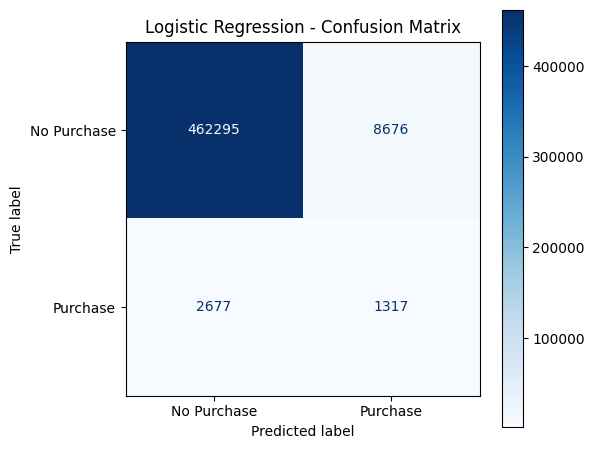

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/ML2_Output"
)
output_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.savefig(
    output_dir / "LR_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:

!pip -q install lightgbm


In [ ]:

import lightgbm as lgb
import numpy as np
import time

print("HUẤN LUYỆN LIGHTGBM")
print("=" * 65)

# Sử dụng cùng 13 feature với Logistic Regression
# LightGBM không bắt buộc chuẩn hóa dữ liệu
X_train_lgb = X_train
X_val_lgb = X_val

# Xử lý mất cân bằng lớp
n_negative = np.sum(y_train == 0)
n_positive = np.sum(y_train == 1)

scale_weight = n_negative / n_positive

print("Scale Pos Weight:", round(scale_weight, 4))

lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start = time.time()

lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=30,
            verbose=False
        )
    ]
)

train_time_lgb = time.time() - start

lgb_val_proba = lgb_model.predict_proba(
    X_val_lgb
)[:, 1]

print("\nHUẤN LUYỆN HOÀN TẤT")
print("Thời gian:", round(train_time_lgb, 2), "giây")
print("Best Iteration:", lgb_model.best_iteration_)

print("\nTHỐNG KÊ XÁC SUẤT:")
print(
    pd.Series(lgb_val_proba).describe(
        percentiles=[.25, .50, .75, .90, .99]
    )
)


HUẤN LUYỆN LIGHTGBM
Scale Pos Weight: 118.5594


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



HUẤN LUYỆN HOÀN TẤT
Thời gian: 32.2 giây
Best Iteration: 1

THỐNG KÊ XÁC SUẤT:
count    474965.000000
mean          0.119357
std           0.160786
min           0.007956
25%           0.031605
50%           0.040071
75%           0.143834
90%           0.408841
99%           0.676335
max           0.676335
dtype: float64


In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("ĐÁNH GIÁ LIGHTGBM")
print("=" * 65)

lgb_roc = roc_auc_score(y_val, lgb_val_proba)
lgb_ap = average_precision_score(y_val, lgb_val_proba)

p, r, thresholds = precision_recall_curve(
    y_val, lgb_val_proba
)

f1_values = (
    2 * p[:-1] * r[:-1]
    / (p[:-1] + r[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
lgb_threshold = thresholds[best_idx]

lgb_pred = (
    lgb_val_proba >= lgb_threshold
).astype(int)

print("ROC-AUC:", round(lgb_roc, 4))
print("Average Precision:", round(lgb_ap, 4))
print("Baseline AP:", round(y_val.mean(), 4))

print("\nBest Threshold:", round(lgb_threshold, 4))

print("Precision:", round(
    precision_score(y_val, lgb_pred), 4
))
print("Recall:", round(
    recall_score(y_val, lgb_pred), 4
))
print("F1-score:", round(
    f1_score(y_val, lgb_pred), 4
))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_val, lgb_pred))


ĐÁNH GIÁ LIGHTGBM
ROC-AUC: 0.8337
Average Precision: 0.0571
Baseline AP: 0.0084

Best Threshold: 0.6629
Precision: 0.0908
Recall: 0.3683
F1-score: 0.1457

CONFUSION MATRIX:
[[456247  14724]
 [  2523   1471]]


In [ ]:

import lightgbm as lgb
import numpy as np
import pandas as pd
import time

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print("TỐI ƯU LIGHTGBM - AVERAGE PRECISION")
print("=" * 65)

# Dùng lại dữ liệu đã tạo cho Logistic Regression
# Giữ tên cột thống nhất để tránh cảnh báo
X_train_lgb = pd.DataFrame(
    X_train, columns=lr_features
)
X_val_lgb = pd.DataFrame(
    X_val, columns=lr_features
)

ratio = (y_train == 0).sum() / (y_train == 1).sum()

configs = {
    "No Weight": 1.0,
    "Sqrt Weight": np.sqrt(ratio),
    "Full Weight": ratio
}

results_lgb = []
models_lgb = {}

for name, weight in configs.items():

    print(f"\nĐANG CHẠY: {name}")
    start = time.time()

    model = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=100,
        colsample_bytree=0.8,
        subsample=0.8,
        subsample_freq=1,
        scale_pos_weight=weight,
        metric="average_precision",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train_lgb,
        y_train,
        eval_set=[(X_val_lgb, y_val)],
        eval_metric="average_precision",
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=40,
                first_metric_only=True,
                verbose=False
            )
        ]
    )

    proba = model.predict_proba(
        X_val_lgb
    )[:, 1]

    ap = average_precision_score(y_val, proba)
    roc = roc_auc_score(y_val, proba)

    elapsed = time.time() - start

    results_lgb.append({
        "Configuration": name,
        "Weight": round(weight, 4),
        "Best Iteration": model.best_iteration_,
        "ROC-AUC": round(roc, 4),
        "AP": round(ap, 4),
        "Time (s)": round(elapsed, 2)
    })

    models_lgb[name] = model

comparison_lgb = pd.DataFrame(results_lgb)

print("\nKẾT QUẢ SO SÁNH:")
display(
    comparison_lgb.sort_values(
        "AP", ascending=False
    )
)


TỐI ƯU LIGHTGBM - AVERAGE PRECISION

ĐANG CHẠY: No Weight

ĐANG CHẠY: Sqrt Weight

ĐANG CHẠY: Full Weight

KẾT QUẢ SO SÁNH:


,Configuration,Weight,Best Iteration,ROC-AUC,AP,Time (s)
0,No Weight,1.0000,119,0.8608,0.1349,70.30
2,Full Weight,118.5594,317,0.8516,0.1308,89.51
1,Sqrt Weight,10.8885,140,0.8594,0.1283,48.88


In [ ]:

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("ĐÁNH GIÁ LIGHTGBM SAU TỐI ƯU")
print("=" * 65)

best_name = comparison_lgb.sort_values(
    "AP", ascending=False
).iloc[0]["Configuration"]

best_lgb_model = models_lgb[best_name]

best_lgb_proba = best_lgb_model.predict_proba(
    X_val_lgb
)[:, 1]

p, r, thresholds = precision_recall_curve(
    y_val, best_lgb_proba
)

f1_values = (
    2 * p[:-1] * r[:-1]
    / (p[:-1] + r[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_lgb_threshold = thresholds[best_idx]

pred = (
    best_lgb_proba >= best_lgb_threshold
).astype(int)

print("Cấu hình tốt nhất:", best_name)
print("Best Iteration:", best_lgb_model.best_iteration_)

print("\nROC-AUC:",
      round(roc_auc_score(y_val, best_lgb_proba), 4))
print("Average Precision:",
      round(average_precision_score(y_val, best_lgb_proba), 4))
print("Best Threshold:",
      round(float(best_lgb_threshold), 4))

print("\nPrecision:",
      round(precision_score(y_val, pred), 4))
print("Recall:",
      round(recall_score(y_val, pred), 4))
print("F1-score:",
      round(f1_score(y_val, pred), 4))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_val, pred))

ĐÁNH GIÁ LIGHTGBM SAU TỐI ƯU
Cấu hình tốt nhất: No Weight
Best Iteration: 119

ROC-AUC: 0.8608
Average Precision: 0.1349
Best Threshold: 0.1217

Precision: 0.1994
Recall: 0.2737
F1-score: 0.2307

CONFUSION MATRIX:
[[466582   4389]
 [  2901   1093]]


In [ ]:

import xgboost as xgb
import numpy as np
import pandas as pd
import time

print("Phiên bản XGBoost:", xgb.__version__)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Số feature:", len(lr_features))


Phiên bản XGBoost: 3.4.1
Train: (1608194, 13)
Validation: (474965, 13)
Số feature: 13


In [ ]:

from xgboost import XGBClassifier

print("HUẤN LUYỆN XGBOOST")
print("=" * 65)

# Sử dụng cùng 13 feature với các mô hình trước
X_train_xgb = pd.DataFrame(
    X_train, columns=lr_features
)

X_val_xgb = pd.DataFrame(
    X_val, columns=lr_features
)

xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=600,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    tree_method="hist",
    scale_pos_weight=1,
    eval_metric="aucpr",
    early_stopping_rounds=40,
    random_state=42,
    n_jobs=-1
)

start = time.time()

xgb_model.fit(
    X_train_xgb,
    y_train,
    eval_set=[(X_val_xgb, y_val)],
    verbose=False
)

xgb_train_time = time.time() - start

xgb_val_proba = xgb_model.predict_proba(
    X_val_xgb
)[:, 1]

print("\nHUẤN LUYỆN HOÀN TẤT")
print("Thời gian:", round(xgb_train_time, 2), "giây")
print("Best Iteration:", xgb_model.best_iteration)

print("\nTHỐNG KÊ XÁC SUẤT:")
print(
    pd.Series(xgb_val_proba).describe(
        percentiles=[.25, .5, .75, .9, .99]
    )
)


HUẤN LUYỆN XGBOOST

HUẤN LUYỆN HOÀN TẤT
Thời gian: 53.41 giây
Best Iteration: 161

THỐNG KÊ XÁC SUẤT:
count    474965.000000
mean          0.009482
std           0.025746
min           0.000247
25%           0.002020
50%           0.003290
75%           0.007367
90%           0.015404
99%           0.131988
max           0.681232
dtype: float64


In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("ĐÁNH GIÁ XGBOOST")
print("=" * 65)

xgb_roc = roc_auc_score(y_val, xgb_val_proba)
xgb_ap = average_precision_score(y_val, xgb_val_proba)

p, r, thresholds = precision_recall_curve(
    y_val, xgb_val_proba
)

f1_values = (
    2 * p[:-1] * r[:-1]
    / (p[:-1] + r[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
xgb_threshold = thresholds[best_idx]

xgb_val_pred = (
    xgb_val_proba >= xgb_threshold
).astype(int)

print("ROC-AUC:", round(xgb_roc, 4))
print("Average Precision:", round(xgb_ap, 4))
print("Baseline AP:", round(y_val.mean(), 4))

print("\nBest Threshold:", round(float(xgb_threshold), 4))

print("Precision:", round(
    precision_score(y_val, xgb_val_pred), 4
))

print("Recall:", round(
    recall_score(y_val, xgb_val_pred), 4
))

print("F1-score:", round(
    f1_score(y_val, xgb_val_pred), 4
))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_val, xgb_val_pred))


ĐÁNH GIÁ XGBOOST
ROC-AUC: 0.8601
Average Precision: 0.1393
Baseline AP: 0.0084

Best Threshold: 0.1097
Precision: 0.185
Recall: 0.3087
F1-score: 0.2313

CONFUSION MATRIX:
[[465538   5433]
 [  2761   1233]]


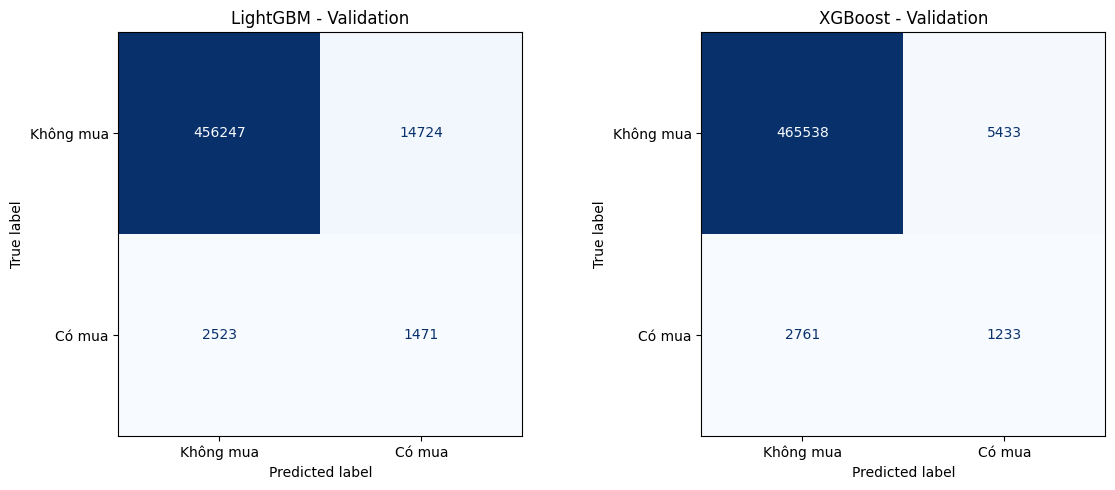

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val, lgb_pred,
    display_labels=["Không mua", "Có mua"],
    cmap="Blues",
    values_format="d",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("LightGBM - Validation")

ConfusionMatrixDisplay.from_predictions(
    y_val, xgb_val_pred,
    display_labels=["Không mua", "Có mua"],
    cmap="Blues",
    values_format="d",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("XGBoost - Validation")

plt.tight_layout()
plt.savefig(
    "ML2_Confusion_Matrix_LGBM_XGB.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:

import numpy as np
import pandas as pd

print("DỰ ĐOÁN TRÊN TẬP TEST")
print("=" * 65)

# Chuẩn bị dữ liệu Test
X_test = X_all[test_idx]
y_test = y_all[test_idx]

# Logistic Regression cần chuẩn hóa
X_test_scaled = scaler.transform(
    X_test
).astype(np.float32)

# LightGBM và XGBoost dùng DataFrame
X_test_tree = pd.DataFrame(
    X_test,
    columns=lr_features
)

# Dự đoán xác suất
lr_test_proba = lr_model.predict_proba(
    X_test_scaled
)[:, 1]

lgb_test_proba = best_lgb_model.predict_proba(
    X_test_tree
)[:, 1]

xgb_test_proba = xgb_model.predict_proba(
    X_test_tree
)[:, 1]

print("Tổng mẫu Test:", len(y_test))
print("Mẫu mua thực tế:", int(y_test.sum()))

print("\nKIỂM TRA XÁC SUẤT:")
for name, p in [
    ("Logistic Regression", lr_test_proba),
    ("LightGBM", lgb_test_proba),
    ("XGBoost", xgb_test_proba)
]:
    print(
        name,
        "| Số mẫu:", len(p),
        "| Hợp lệ:",
        bool(np.isfinite(p).all()),
        "| Trong [0,1]:",
        bool(((p >= 0) & (p <= 1)).all())
    )


DỰ ĐOÁN TRÊN TẬP TEST
Tổng mẫu Test: 262313
Mẫu mua thực tế: 2038

KIỂM TRA XÁC SUẤT:
Logistic Regression | Số mẫu: 262313 | Hợp lệ: True | Trong [0,1]: True
LightGBM | Số mẫu: 262313 | Hợp lệ: True | Trong [0,1]: True
XGBoost | Số mẫu: 262313 | Hợp lệ: True | Trong [0,1]: True


In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

print("EVALUATION - FINAL TEST")
print("=" * 65)

model_results = [
    ("Logistic Regression", lr_test_proba, best_threshold),
    ("LightGBM", lgb_test_proba, best_lgb_threshold),
    ("XGBoost", xgb_test_proba, xgb_threshold)
]

rows = []

for name, proba, threshold in model_results:

    pred = (proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "AP": average_precision_score(y_test, proba),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "Accuracy": accuracy_score(y_test, pred),
        "Threshold": float(threshold),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    })

evaluation_df = pd.DataFrame(rows)

print("\nBẢNG SO SÁNH TEST:")
display(evaluation_df.round(4))

print("\nBASELINE AP:")
print(round(y_test.mean(), 4))


EVALUATION - FINAL TEST

BẢNG SO SÁNH TEST:


,Model,ROC-AUC,AP,Precision,Recall,F1,Accuracy,Threshold,TP,FP,TN,FN
0,Logistic Regression,0.8285,0.0752,0.1085,0.3283,0.1631,0.9738,0.9453,669,5498,254777,1369
1,LightGBM,0.8545,0.1032,0.1501,0.2345,0.1830,0.9837,0.1217,478,2707,257568,1560
2,XGBoost,0.8545,0.1115,0.1421,0.2723,0.1867,0.9816,0.1097,555,3351,256924,1483



BASELINE AP:
0.0078


In [ ]:

from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/ML2_Output"
)
output_dir.mkdir(parents=True, exist_ok=True)

path = output_dir / "ML2_Final_Model_Comparison.csv"

evaluation_df.to_csv(
    path,
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu:", path)


Đã lưu: /content/drive/MyDrive/Retailrocket_BigData/ML2_Output/ML2_Final_Model_Comparison.csv


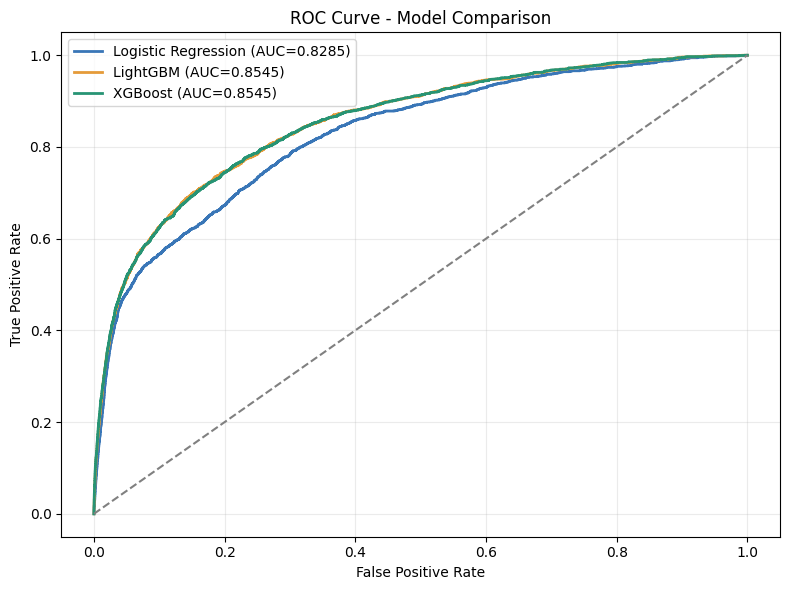

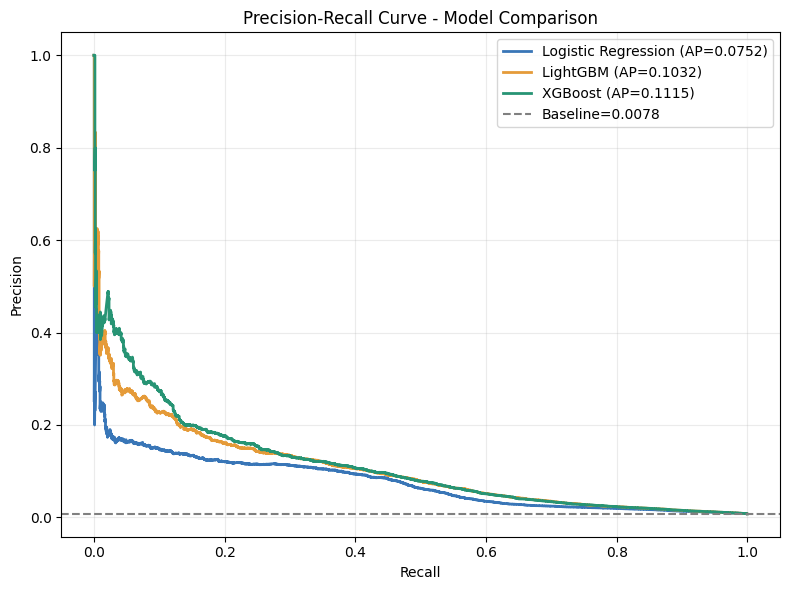

Đã lưu 2 biểu đồ Evaluation vào Google Drive.


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/ML2_Output"
)
output_dir.mkdir(parents=True, exist_ok=True)

models = {
    "Logistic Regression": lr_test_proba,
    "LightGBM": lgb_test_proba,
    "XGBoost": xgb_test_proba
}

colors = {
    "Logistic Regression": "#3976B7",
    "LightGBM": "#E59B39",
    "XGBoost": "#279474"
}

# HÌNH 1: ROC CURVE
plt.figure(figsize=(8, 6))

for name, proba in models.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc:.4f})",
        color=colors[name],
        linewidth=2
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    output_dir / "ML2_ROC_Curve_Test.png",
    dpi=300
)
plt.show()

# HÌNH 2: PRECISION-RECALL CURVE
plt.figure(figsize=(8, 6))

for name, proba in models.items():
    precision, recall, _ = precision_recall_curve(
        y_test, proba
    )

    ap = average_precision_score(y_test, proba)

    plt.plot(
        recall, precision,
        label=f"{name} (AP={ap:.4f})",
        color=colors[name],
        linewidth=2
    )

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label=f"Baseline={y_test.mean():.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Model Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    output_dir / "ML2_PR_Curve_Test.png",
    dpi=300
)
plt.show()

print("Đã lưu 2 biểu đồ Evaluation vào Google Drive.")


In [ ]:

import numpy as np
import pandas as pd
import shap
import xgboost as xgb
import matplotlib.pyplot as plt

print("CHUẨN BỊ DỮ LIỆU SHAP")
print("=" * 65)

# Lấy ngẫu nhiên 6.000 mẫu từ tập Test
rng = np.random.default_rng(42)

sample_size = min(6000, len(X_test_tree))

sample_idx = rng.choice(
    len(X_test_tree),
    size=sample_size,
    replace=False
)

X_shap = X_test_tree.iloc[
    sample_idx
].copy().reset_index(drop=True)

y_shap = y_test[sample_idx]

print("Số mẫu SHAP:", len(X_shap))
print("Số đặc trưng:", X_shap.shape[1])

print("Số mẫu mua thực tế:", int(y_shap.sum()))
print("Số mẫu không mua:", int((y_shap == 0).sum()))

print("\nTỷ lệ nhãn dương mẫu SHAP:",
      round(y_shap.mean() * 100, 4), "%")

print("\nTỶ LỆ NHÃN DƯƠNG TẬP TEST:",
      round(y_test.mean() * 100, 4), "%")

print("\nDanh sách đặc trưng:")
print(X_shap.columns.tolist())


CHUẨN BỊ DỮ LIỆU SHAP
Số mẫu SHAP: 6000
Số đặc trưng: 13
Số mẫu mua thực tế: 48
Số mẫu không mua: 5952

Tỷ lệ nhãn dương mẫu SHAP: 0.8 %

TỶ LỆ NHÃN DƯƠNG TẬP TEST: 0.7769 %

Danh sách đặc trưng:
['first_event_cart', 'user_prior_views_log', 'user_prior_carts_log', 'item_prior_views_log', 'item_prior_carts_log', 'prior_view_count_log', 'prior_cart_count_log', 'hour', 'day_of_week', 'has_prior_interaction', 'recency_hours_clean', 'previous_event_cart', 'user_view_to_cart_flag']


In [ ]:

print("TÍNH GIÁ TRỊ SHAP - XGBOOST")
print("=" * 65)

booster = xgb_model.get_booster()

dm_shap = xgb.DMatrix(
    X_shap,
    feature_names=lr_features
)

# Chỉ sử dụng cây đến Best Iteration
best_round = xgb_model.best_iteration + 1

contributions = booster.predict(
    dm_shap,
    pred_contribs=True,
    iteration_range=(0, best_round)
)

# Cột cuối cùng là base value
shap_values = contributions[:, :-1]
base_values = contributions[:, -1]

# Tạo đối tượng Explanation để vẽ biểu đồ
shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=base_values,
    data=X_shap.to_numpy(),
    feature_names=lr_features
)

print("Kích thước SHAP:", shap_values.shape)

print("\nKIỂM TRA TÍNH NHẤT QUÁN:")

raw_margin = booster.predict(
    dm_shap,
    output_margin=True,
    iteration_range=(0, best_round)
)

reconstructed = (
    shap_values.sum(axis=1) + base_values
)

max_difference = np.max(
    np.abs(raw_margin - reconstructed)
)

print("Sai lệch lớn nhất:",
      float(max_difference))

print("Hợp lệ:",
      bool(np.allclose(
          raw_margin,
          reconstructed,
          atol=1e-4
      )))


TÍNH GIÁ TRỊ SHAP - XGBOOST
Kích thước SHAP: (6000, 13)

KIỂM TRA TÍNH NHẤT QUÁN:
Sai lệch lớn nhất: 4.76837158203125e-06
Hợp lệ: True


SHAP FEATURE IMPORTANCE
BẢNG XẾP HẠNG ĐẶC TRƯNG:


,Feature,Mean_Absolute_SHAP
0,item_prior_carts_log,0.644943
1,user_prior_carts_log,0.499979
2,item_prior_views_log,0.258333
3,day_of_week,0.132188
4,hour,0.121714
5,first_event_cart,0.108283
6,recency_hours_clean,0.105387
7,prior_view_count_log,0.083061
8,user_prior_views_log,0.061508
9,previous_event_cart,0.031418


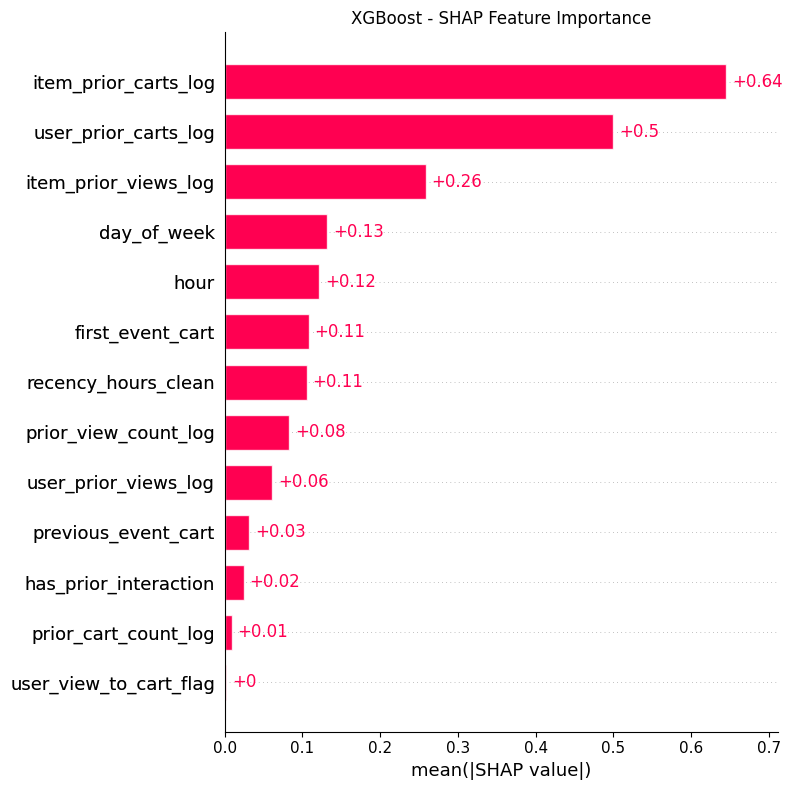

In [ ]:

from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/ML2_Output"
)
output_dir.mkdir(parents=True, exist_ok=True)

print("SHAP FEATURE IMPORTANCE")
print("=" * 65)

importance = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": lr_features,
    "Mean_Absolute_SHAP": importance
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("BẢNG XẾP HẠNG ĐẶC TRƯNG:")
display(shap_importance_df.round(6))

plt.figure(figsize=(9, 6))

shap.plots.bar(
    shap_explanation,
    max_display=13,
    show=False
)

plt.title("XGBoost - SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    output_dir / "ML2_SHAP_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Xuất bảng kết quả
shap_importance_df.to_csv(
    output_dir / "ML2_SHAP_Importance.csv",
    index=False,
    encoding="utf-8-sig"
)


SHAP BEESWARM - XGBOOST


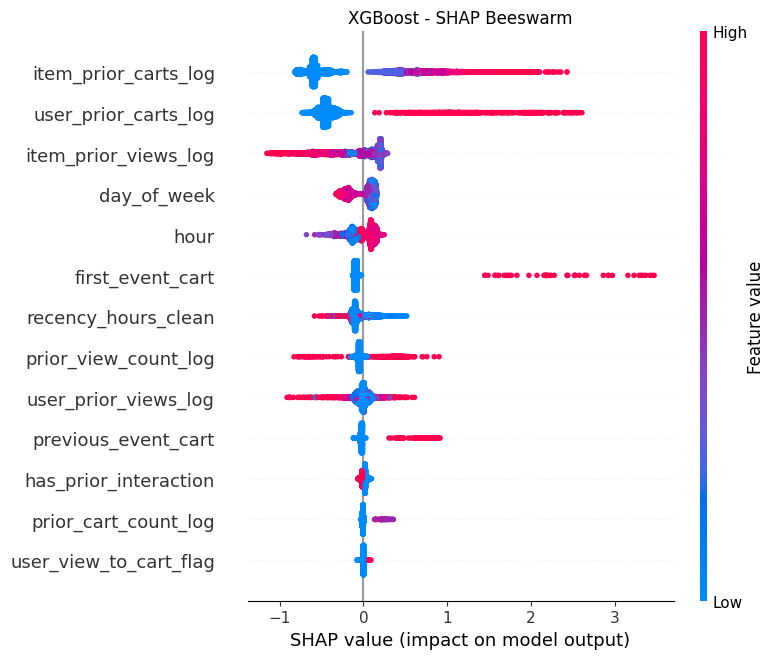

Đã lưu SHAP Beeswarm.


In [ ]:

print("SHAP BEESWARM - XGBOOST")
print("=" * 65)

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_explanation,
    max_display=13,
    show=False
)

plt.title("XGBoost - SHAP Beeswarm")
plt.tight_layout()

plt.savefig(
    output_dir / "ML2_SHAP_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu SHAP Beeswarm.")


SHAP DEPENDENCE PLOT
Đặc trưng quan trọng nhất: item_prior_carts_log


<Figure size 900x500 with 0 Axes>

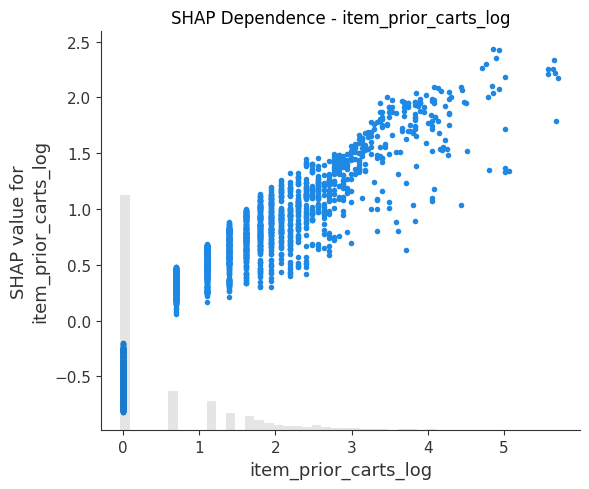

In [ ]:

print("SHAP DEPENDENCE PLOT")
print("=" * 65)

top_feature = shap_importance_df.iloc[0]["Feature"]

print("Đặc trưng quan trọng nhất:", top_feature)

plt.figure(figsize=(9, 5))

shap.plots.scatter(
    shap_explanation[:, top_feature],
    show=False
)

plt.title(f"SHAP Dependence - {top_feature}")
plt.tight_layout()

plt.savefig(
    output_dir / "ML2_SHAP_Dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

import pandas as pd
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Retailrocket_BigData/ML2_Output"
)

output_dir.mkdir(parents=True, exist_ok=True)

# 1. Bảng so sánh hiệu suất mô hình
evaluation_df.to_csv(
    output_dir / "ML2_Model_Performance_PowerBI.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. Dữ liệu dự đoán trên tập Test
predictions_df = ml2_features.iloc[test_idx][
    [
        "visitorid",
        "session_id",
        "itemid",
        "prediction_datetime",
        "first_event",
        "purchase_intention"
    ]
].copy().reset_index(drop=True)

predictions_df["LR_Probability"] = lr_test_proba
predictions_df["LightGBM_Probability"] = lgb_test_proba
predictions_df["XGBoost_Probability"] = xgb_test_proba

# Ngưỡng chọn từ Validation
predictions_df["XGBoost_Predicted"] = (
    predictions_df["XGBoost_Probability"]
    >= xgb_threshold
).astype(int)

predictions_df.to_csv(
    output_dir / "ML2_Predictions_PowerBI.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. Bảng giải thích SHAP
shap_importance_df.to_csv(
    output_dir / "ML2_SHAP_PowerBI.csv",
    index=False,
    encoding="utf-8-sig"
)

print("XUẤT DỮ LIỆU POWER BI THÀNH CÔNG")
print("=" * 65)

for file in [
    "ML2_Model_Performance_PowerBI.csv",
    "ML2_Predictions_PowerBI.csv",
    "ML2_SHAP_PowerBI.csv"
]:
    path = output_dir / file
    print(file, "|", round(path.stat().st_size / 1024**2, 2), "MB")


XUẤT DỮ LIỆU POWER BI THÀNH CÔNG
ML2_Model_Performance_PowerBI.csv | 0.0 MB
ML2_Predictions_PowerBI.csv | 29.64 MB
ML2_SHAP_PowerBI.csv | 0.0 MB
